# Chapter 7 — Inverse Position Kinematics

Chapter 5 answered *where is the gripper, given the joints?* This chapter answers the
reverse question, the one a robot faces every time it is told to pick something up:

> **Inverse position kinematics (IK):** given a desired gripper pose, or part of it (for
> example a position and a pointing direction), find joint variables $\boldsymbol\theta$
> that put the gripper there.

Forward kinematics is a recipe: multiply the matrices and you get exactly one answer.
Inverse kinematics means solving nonlinear trigonometric equations, and the answer may not
exist, may be one of several, or may not be unique at all. There are two ways to solve them:

- **Analytical (closed-form) IK** uses geometry (triangles, `atan2`, the law of cosines)
  to write each joint variable as a formula. It is fast and exact and gives every solution,
  but it has to be derived by hand for each robot.
- **Numerical IK** starts from a guess and repeatedly corrects it with the Jacobian of
  Chapter 6 until the forward kinematics hits the target. It works for any robot whose
  forward kinematics we can compute, but it returns one solution (the one near the guess)
  and needs care near singularities and joint limits.


| Section | Topic |
|---------|-------|
| 7.1 | The IK problem: existence, multiple solutions, workspace |
| 7.2 | Analytical toolkit: `atan2`, law of cosines, $a\cos\theta + b\sin\theta = c$, decoupling|
| 7.3 | Analytical examples: planar 3R, SCARA, spherical wrist, 6-joint arms|
| 7.4 | SO-ARM101 analytical IK (position + pitch)|
| 7.5 | Numerical IK: Newton, pseudo-inverse, Jacobian transpose, damped least squares, optimization-based IK |
| 7.6 | Numerical examples: planar 2R, SO-ARM101, UR5e|
| 7.7 | Analytical vs. numerical, and chapter summary|

**Notation** (same as Chapters 5 and 6). $\mathbf{T}_e^0(\boldsymbol\theta)$ is the gripper
pose, $\mathbf{p} = \mathbf{o}_e$ its position (last column) and $\mathbf{R}_e^0$ its
orientation. A subscript $d$ marks a *desired* value: $\mathbf{p}_d$, $\mathbf{R}_d$,
$\varphi_d$. The code works in radians and prints degrees.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time
from pathlib import Path
from types import SimpleNamespace
from ipywidgets import interact, FloatSlider, Dropdown
%matplotlib inline

np.set_printoptions(precision=4, suppress=True)

### Tools and robots from Chapters 5 and 6

The next cell collects the forward-kinematics tools of Chapter 5 (basic HTMs, the `Robot`
class, drawing helpers), the `jacobian` function of Chapter 6, and the robots we reuse.
It adds two robots: a planar 3R arm, and the **SO-ARM101**, built from the `pos` and `quat`
of each body in its MuJoCo model (`so101_new_calib.xml`). This chain reproduces MuJoCo's own
`gripperframe` site to about $10^{-8}$ m (we check this in Section 7.6.2).
Run the cell and move on.

In [3]:
# ── Basic HTMs ─────────────────────────────────────────────────────────────────
def Trans(axis, d):
    T = np.eye(4)
    T['xyz'.index(axis), 3] = d
    return T


def Rot(axis, theta):
    c, s = np.cos(theta), np.sin(theta)
    R = {'x': [[1, 0, 0], [0, c, -s], [0, s, c]],
         'y': [[c, 0, s], [0, 1, 0], [-s, 0, c]],
         'z': [[c, -s, 0], [s, c, 0], [0, 0, 1]]}[axis]
    T = np.eye(4)
    T[:3, :3] = R
    return T


def show(M, name='M'):
    print(f'{name} =')
    print(np.round(M, 4) + 0.0)


# ── Factors and the three-step FK procedure (Chapter 5, Section 5.3) ──────────
def Tr(axis, val, tex):
    return dict(kind='trans', axis=axis, val=val, tex=rf'\mathrm{{Trans}}_{{{axis},{tex}}}')


def Rt(axis, val, tex):
    return dict(kind='rot', axis=axis, val=val, tex=rf'\mathrm{{Rot}}_{{{axis},{tex}}}')


def factor_T(f):
    return Trans(f['axis'], f['val']) if f['kind'] == 'trans' else Rot(f['axis'], f['val'])


class Robot:
    #   home   : home[i] = list of factors whose product is T_{i+1}^{i}(0)
    #   joints : list of (slider label, LaTeX symbol, 'R' or 'P', (min, max))
    #   tool   : list of factors whose product is the constant T_e^n
    def __init__(self, name, home, joints, tool):
        self.name, self.home, self.joints, self.tool = name, home, joints, tool
        self.n = len(joints)
        self.types = [j[2] for j in joints]

    def groups(self, q):
        G = []
        for i, (_, tex, jtype, _) in enumerate(self.joints):
            motion = Rt('z', q[i], tex) if jtype == 'R' else Tr('z', q[i], tex)
            G.append((str(i + 1), self.home[i] + [motion]))
        G.append(('e', self.tool))
        return G

    def frames(self, q):
        # {'0': I, '1': T_1^0, ..., 'n': T_n^0, 'e': T_e^0}
        T, out = np.eye(4), {'0': np.eye(4)}
        for name, factors in self.groups(q):
            for f in factors:
                T = T @ factor_T(f)
            out[name] = T
        return out

    def fk(self, q):
        return self.frames(q)['e']


# ── The four robots of this chapter (same frames and dimensions as Chapter 5) ──
def make_2R(L1=1.0, L2=0.7):
    return Robot('Planar 2R', home=[[], [Tr('x', L1, 'L_1')]],
                 joints=[('θ₁', r'\theta_1', 'R', (-180, 180)), ('θ₂', r'\theta_2', 'R', (-180, 180))],
                 tool=[Tr('x', L2, 'L_2')])


def make_wrist(L=0.6):
    return Robot('Spherical wrist', home=[[], [Rt('x', -np.pi/2, r'-90^\circ')], [Rt('x', np.pi/2, r'90^\circ')]],
                 joints=[('θ₁', r'\theta_1', 'R', (-180, 180)), ('θ₂', r'\theta_2', 'R', (-180, 180)),
                         ('θ₃', r'\theta_3', 'R', (-180, 180))],
                 tool=[Tr('z', L, 'L')])


def make_scara(h=0.8, L1=0.8, L2=0.6, de=0.15):
    return Robot('SCARA', home=[[Tr('z', h, 'h')], [Tr('x', L1, 'L_1')],
                                [Tr('x', L2, 'L_2'), Rt('x', np.pi, r'180^\circ')], []],
                 joints=[('θ₁', r'\theta_1', 'R', (-180, 180)), ('θ₂', r'\theta_2', 'R', (-180, 180)),
                         ('d₃', 'd_3', 'P', (0, 0.6)), ('θ₄', r'\theta_4', 'R', (-180, 180))],
                 tool=[Tr('z', de, 'd_e')])


def make_ur5e(d1=0.163, a2=0.425, a3=0.392, d4=0.134, d5=0.100, d6=0.100):
    return Robot('UR5e', home=[[Tr('z', d1, 'd_1')], [Rt('x', np.pi/2, r'90^\circ')],
                               [Tr('x', -a2, '-a_2')], [Tr('x', -a3, '-a_3')],
                               [Tr('z', d4, 'd_4'), Rt('x', np.pi/2, r'90^\circ')],
                               [Tr('z', d5, 'd_5'), Rt('x', -np.pi/2, r'-90^\circ')]],
                 joints=[(f'θ{s}', rf'\theta_{i}', 'R', (-180, 180)) for i, s in zip(range(1, 7), '₁₂₃₄₅₆')],
                 tool=[Tr('z', d6, 'd_6')])


def make_3R(L1=1.0, L2=0.7, L3=0.3):
    return Robot('Planar 3R', home=[[], [Tr('x', L1, 'L_1')], [Tr('x', L2, 'L_2')]],
                 joints=[(f'θ{s}', rf'\theta_{i}', 'R', (-180, 180)) for i, s in zip((1, 2, 3), '₁₂₃')],
                 tool=[Tr('x', L3, 'L_3')])


robot_2R, robot_3R, robot_wrist = make_2R(), make_3R(), make_wrist()
robot_scara, robot_ur5e = make_scara(), make_ur5e()


# ── Drawing helpers ────────────────────────────────────────────────────────────
AXIS_COLORS = ('red', 'green', 'blue')
V_COLOR, W_COLOR = 'black', 'purple'          # linear and angular velocity arrows


def draw_frame(ax, T, name='', scale=0.3, alpha=1.0, lw=2.0):
    o = T[:3, 3]
    for i, col in enumerate(AXIS_COLORS):
        ax.quiver(*o, *(T[:3, i] * scale), color=col, alpha=alpha, linewidth=lw, arrow_length_ratio=0.2)
    if name:
        ax.text(*(o - 0.25 * scale), f'{{{name}}}', fontsize=9, fontweight='bold')


def arrow(ax, p, v, color, lw=2.5):
    if np.linalg.norm(v) > 1e-9:
        ax.quiver(*p, *v, color=color, linewidth=lw, arrow_length_ratio=0.15)


def setup_3d(ax, center=(0, 0, 0), half=1.0, view=(25, -60), title='', zhalf=None):
    c = np.asarray(center, float)
    zh = half if zhalf is None else zhalf
    ax.set_xlim(c[0] - half, c[0] + half)
    ax.set_ylim(c[1] - half, c[1] + half)
    ax.set_zlim(c[2] - zh, c[2] + zh)
    ax.set_box_aspect((1, 1, zh / half))
    ax.set_xlabel('$x_0$'); ax.set_ylabel('$y_0$'); ax.set_zlabel('$z_0$')
    ax.view_init(*view)
    if title:
        ax.set_title(title, fontsize=11)


def plot_robot(ax, robot, q, scale=0.2, alpha=1.0, axes=False):
    # Links as a polyline through the frame origins, plus frames {0} and {e}.
    # axes=True also draws every joint axis as a dashed line through o_i along z_i.
    F = robot.frames(q)
    pts = np.array([T[:3, 3] for T in F.values()])
    ax.plot(*pts.T, color='0.5', lw=6, alpha=alpha, solid_capstyle='round', zorder=0)
    ax.scatter(*pts[:-1].T, color='0.25', s=35, alpha=alpha)
    if alpha == 1.0:
        draw_frame(ax, np.eye(4), '0', scale * 1.2)
        draw_frame(ax, F['e'], 'e', scale)
    if axes:
        for i in range(robot.n):
            o, z = F[str(i + 1)][:3, 3], F[str(i + 1)][:3, 2]
            seg = np.array([o - 0.35 * z, o + 0.35 * z])
            ax.plot(*seg.T, ls='--', lw=1, color='tab:blue', alpha=0.8)
    return F




# ── Jacobian by the column formula (Chapter 6, Section 6.2) ───────────────────
def jacobian(robot, q):
    F = robot.frames(q)
    o_e = F['e'][:3, 3]
    J = np.zeros((6, robot.n))
    for i, jtype in enumerate(robot.types):
        z_i, o_i = F[str(i + 1)][:3, 2], F[str(i + 1)][:3, 3]
        if jtype == 'R':
            J[:3, i], J[3:, i] = np.cross(z_i, o_e - o_i), z_i
        else:
            J[:3, i] = z_i
    return J


def wrap(angle):
    # Wrap angles to (-pi, pi]
    return (np.asarray(angle) + np.pi) % (2 * np.pi) - np.pi


# ── The SO-ARM101: body frames of the MuJoCo model so101_new_calib.xml ──
def quat_to_R(w, x, y, z):
    # Rotation matrix of the quaternion (w, x, y, z) (Chapter 4)
    n = np.sqrt(w*w + x*x + y*y + z*z)
    w, x, y, z = w / n, x / n, y / n, z / n
    return np.array([[1 - 2*(y*y + z*z), 2*(x*y - w*z),     2*(x*z + w*y)],
                     [2*(x*y + w*z),     1 - 2*(x*x + z*z), 2*(y*z - w*x)],
                     [2*(x*z - w*y),     2*(y*z + w*x),     1 - 2*(x*x + y*y)]])


def HTM(R, o):
    T = np.eye(4)
    T[:3, :3], T[:3, 3] = R, o
    return T


#   joint             o_i^{i-1} = MJCF pos (m)             MJCF quat -> R_i^{i-1}(0)
SO101_LINKS = [
    ('shoulder_pan',  [0.0388353, 0.0, 0.0624],          (0, 0, -1, 0)),
    ('shoulder_lift', [-0.0303992, -0.0182778, -0.0542], (0.5, -0.5, -0.5, -0.5)),
    ('elbow_flex',    [-0.11257, -0.028, 0.0],           (0.707107, 0, 0, 0.707107)),
    ('wrist_flex',    [-0.1349, 0.0052, 0.0],            (0.707107, 0, 0, -0.707107)),
    ('wrist_roll',    [0.0, -0.0611, 0.0181],            (0.0172091, -0.0172091, 0.706897, 0.706897)),
]
SO101_Te5 = HTM(quat_to_R(0.707107, 0, 0.707107, 0), [-0.0079, -0.000218121, -0.0981274])  # gripperframe site
SO101_LIMITS_DEG = [(-110, 110), (-100, 100), (-96.8, 96.8), (-95, 95), (-157.2, 162.8)]


class SO101:
    # Same interface as Robot (frames, fk, n, types, joints), so jacobian() and plot_robot() work.
    def __init__(self):
        self.name, self.n, self.types = 'SO-ARM101', 5, 'RRRRR'
        self.joints = [(name, rf'\theta_{i + 1}', 'R', lim)
                       for i, ((name, _, _), lim) in enumerate(zip(SO101_LINKS, SO101_LIMITS_DEG))]
        self.home = [HTM(quat_to_R(*quat), o) for _, o, quat in SO101_LINKS]   # T_i^{i-1}(0)
        self.lo = np.radians([lo for lo, _ in SO101_LIMITS_DEG])
        self.hi = np.radians([hi for _, hi in SO101_LIMITS_DEG])

    def frames(self, q):
        T, out = np.eye(4), {'0': np.eye(4)}
        for i, (T_home, qi) in enumerate(zip(self.home, q)):
            T = T @ T_home @ Rot('z', qi)          # T_i^{i-1}(θ_i) = T_i^{i-1}(0) Rot_{z,θ_i}
            out[str(i + 1)] = T
        out['e'] = T @ SO101_Te5
        return out

    def fk(self, q):
        return self.frames(q)['e']

    def within_limits(self, q, tol=1e-9):
        return bool(np.all(q >= self.lo - tol) and np.all(q <= self.hi + tol))


so101 = SO101()
view_so101 = dict(center=(0.17, 0.0, 0.12), half=0.2, view=(25, -60))
print('Robots ready:', ', '.join(r.name for r in (robot_2R, robot_3R, robot_wrist, robot_scara, robot_ur5e, so101)))

Robots ready: Planar 2R, Planar 3R, Spherical wrist, SCARA, UR5e, SO-ARM101


## 7.1  The IK Problem

**Forward vs. inverse.** Forward kinematics maps joints to pose,
$\boldsymbol\theta \mapsto \mathbf{T}_e^0(\boldsymbol\theta)$: one product of matrices, always
exactly one answer. Inverse kinematics asks for the joints that solve

$$\mathbf{T}_e^0(\boldsymbol\theta) = \mathbf{T}_d .$$

This $4\times4$ equation hides 12 nonlinear equations in $\cos\theta_i$ and $\sin\theta_i$
(9 rotation entries and 3 position entries), but only **6 are independent**: 3 for position
and 3 for orientation, because only 3 of the 9 numbers in a rotation matrix are free
(Chapter 4).

**Count equations and unknowns.** Let $m$ be the number of task coordinates we ask for and
$n$ the number of joints:

| Robot | What we ask for | $m$ | $n$ | Typical number of solutions |
|---|---|---|---|---|
| Planar 2R | $(x, y)$ | 2 | 2 | 0, 1 or 2 |
| Planar 3R | $(x, y, \varphi)$ | 3 | 3 | 0, 1 or 2 |
| SCARA | $(x, y, z, \text{yaw})$ | 4 | 4 | 0, 1 or 2 |
| SO-ARM101 | $(x, y, z, \text{pitch})$; roll $\theta_5$ set directly | 4 | 4 (+1) | up to 4, but only 1 within the joint limits |
| UR5e | full pose | 6 | 6 | up to 8 |
| 7-joint arm (e.g. Franka) | full pose | 6 | 7 | infinitely many |

So there are three possible outcomes:

1. **No solution.** The target is outside the workspace, asks for an orientation the robot
   cannot produce (a 5-joint arm cannot reach an arbitrary 6-number pose), or every
   solution violates a joint limit.
2. **A finite number of solutions** ($m = n$). They differ by discrete **branches**: elbow up
   or down, shoulder left or right, wrist flipped. A general 6R arm can have up to 16.
3. **Infinitely many solutions.** When $n > m$ the robot is **redundant**: it can move its
   joints without moving the gripper (*self-motion*). This also happens at some singular
   configurations, such as the aligned spherical wrist of Section 6.5.2.

**Workspace.** The *reachable workspace* is the set of gripper positions the robot can
reach with at least one orientation; the *dexterous workspace* is the smaller set it can
reach with every orientation. For the planar 2R arm the reachable workspace is the annulus
$|L_1 - L_2| \le \|\mathbf{p}\| \le L_1 + L_2$ (Section 3.2.1), and joint limits shrink it
further.

<p align="center"><img src="Fig7-01_2R_solutions.png" width="900"></p>

<p align="center"><i>Figure 7.1 — The planar 2R arm (L<sub>1</sub> = 1, L<sub>2</sub> = 0.7): two solutions inside the workspace, one on its boundary, none outside.</i></p>

**The 2R solution, again.** Section 3.2.2 solved the 2R arm by geometry, and that solution is
the template for everything in this chapter:

$$\cos\theta_2 = \frac{x_d^2 + y_d^2 - L_1^2 - L_2^2}{2L_1L_2},\qquad
\theta_2 = \mathrm{atan2}\!\left(\pm\sqrt{1-\cos^2\theta_2},\ \cos\theta_2\right),\qquad
\theta_1 = \mathrm{atan2}(y_d, x_d) - \mathrm{atan2}(L_2\sin\theta_2,\ L_1 + L_2\cos\theta_2).$$

The $\pm$ is the branch choice. With $L_1 = 1$, $L_2 = 0.7$ (the arm of Chapters 5 and 6),
$\theta_2 > 0$ is the elbow-down solution in Figure 7.1(a).

In [4]:
def ik_2R_all(x, y, L1=1.0, L2=0.7):
    # All IK solutions of the planar 2R arm, as a list of arrays (θ1, θ2).
    c2 = (x**2 + y**2 - L1**2 - L2**2) / (2 * L1 * L2)
    if abs(c2) > 1 + 1e-12:
        return []                                         # outside the workspace
    s2 = np.sqrt(max(0.0, 1 - c2**2))
    sols = []
    for s in ([s2, -s2] if s2 > 1e-6 else [0.0]):         # one solution on the boundary
        th2 = np.arctan2(s, c2)
        th1 = np.arctan2(y, x) - np.arctan2(L2 * s, L1 + L2 * c2)
        sols.append(np.array([th1, th2]))
    return sols


for target in [(1.05, 0.75), (1.7 * np.cos(0.5), 1.7 * np.sin(0.5)), (1.75, 0.75)]:
    sols = ik_2R_all(*target)
    print(f'target ({target[0]:.3f}, {target[1]:.3f}): {len(sols)} solution(s)')
    for q in sols:
        p = robot_2R.fk(q)[:2, 3]
        print(f'    θ = {np.round(np.degrees(q), 2)}°    FK check: p = {np.round(p, 4)}')

target (1.050, 0.750): 2 solution(s)
    θ = [ 2.97 82.82]°    FK check: p = [1.05 0.75]
    θ = [ 68.1  -82.82]°    FK check: p = [1.05 0.75]
target (1.492, 0.815): 1 solution(s)
    θ = [28.65  0.  ]°    FK check: p = [1.4919 0.815 ]
target (1.750, 0.750): 0 solution(s)


Every analytical solution in this chapter should end the same way: **plug the answer back
into the forward kinematics and confirm that it reproduces the target.**

> **Key Takeaways — Section 7.1**
> - IK solves $\mathbf{T}_e^0(\boldsymbol\theta) = \mathbf{T}_d$: nonlinear equations with 0, finitely many, or infinitely many solutions.
> - Compare $m$ (task coordinates asked for) with $n$ (joints): $m = n$ gives discrete branches, $n > m$ gives redundancy, $m > n$ asks for too much.
> - Reachable vs. dexterous workspace; joint limits remove solutions.
> - Always check an IK answer with the forward kinematics.

## 7.2  The Analytical Toolkit

Almost every closed-form IK solution is built from four tools.

### 7.2.1  Use `atan2`, not `acos` or `asin` alone

`acos` returns angles in $[0, \pi]$ and loses the sign; `asin` returns angles in
$[-\pi/2, \pi/2]$ and loses the back half of the circle. Both are also inaccurate near
$\pm1$, where a tiny error in the input becomes a large error in the angle. The rule:

> **Find both $\sin\theta$ and $\cos\theta$ (or two numbers proportional to them with the
> same positive factor), then take $\theta = \mathrm{atan2}(\sin\theta, \cos\theta)$.**

The 2R solution does exactly this: $\cos\theta_2$ comes from the law of cosines, and
$\sin\theta_2 = \pm\sqrt{1-\cos^2\theta_2}$, where the sign is the branch we choose.

In [5]:
theta = np.radians(-120)
c, s = np.cos(theta), np.sin(theta)
print(f'true angle      = {np.degrees(theta):8.2f}°')
print(f'acos(c)         = {np.degrees(np.arccos(c)):8.2f}°   wrong sign')
print(f'asin(s)         = {np.degrees(np.arcsin(s)):8.2f}°   wrong half of the circle')
print(f'atan2(s, c)     = {np.degrees(np.arctan2(s, c)):8.2f}°   correct')
print(f'atan2(5s, 5c)   = {np.degrees(np.arctan2(5 * s, 5 * c)):8.2f}°   a common positive factor does not matter')

true angle      =  -120.00°
acos(c)         =   120.00°   wrong sign
asin(s)         =   -60.00°   wrong half of the circle
atan2(s, c)     =  -120.00°   correct
atan2(5s, 5c)   =  -120.00°   a common positive factor does not matter


### 7.2.2  The law of cosines

Two links of lengths $L_1$ and $L_2$ joined by a revolute joint, and a distance $D$ between
their free ends, form a triangle. The joint angle $\theta_2$ is the *bend* between the links
(the exterior angle), so the interior angle is $\pi - \theta_2$ and

$$D^2 = L_1^2 + L_2^2 - 2L_1L_2\cos(\pi - \theta_2) = L_1^2 + L_2^2 + 2L_1L_2\cos\theta_2
\quad\Longrightarrow\quad
\boxed{\cos\theta_2 = \frac{D^2 - L_1^2 - L_2^2}{2L_1L_2}}$$

- $|\cos\theta_2| > 1$: no triangle exists, so the target is out of reach.
- Otherwise there are two mirror-image triangles, $\sin\theta_2 = \pm\sqrt{1-\cos^2\theta_2}$: the two branches.
- The direction of the first link is then the direction of the target minus the angle
  that link 2 adds: $\theta_1 = \mathrm{atan2}(y,x) - \mathrm{atan2}(L_2\sin\theta_2,\ L_1+L_2\cos\theta_2)$.

### 7.2.3  The equation $a\cos\theta + b\sin\theta = c$

This equation appears whenever one joint has to rotate a point onto a line or a plane, for
example when the plane of an arm is offset sideways from the base axis (we meet it on the
SO-ARM101 in Section 7.4.5). Write $(a, b)$ in polar form, $a = \rho\cos\gamma$,
$b = \rho\sin\gamma$ with $\rho = \sqrt{a^2+b^2}$ and $\gamma = \mathrm{atan2}(b, a)$. Then
$a\cos\theta + b\sin\theta = \rho\cos(\theta - \gamma) = c$, so

$$\boxed{\theta = \mathrm{atan2}(b, a) \pm \mathrm{atan2}\!\left(\sqrt{a^2 + b^2 - c^2},\ c\right)}$$

- It has a solution only if $c^2 \le a^2 + b^2$.
- In general there are two solutions; there is one when $c^2 = a^2 + b^2$.
- The special case $c = 0$ gives $\theta = \mathrm{atan2}(b, a) \pm 90^\circ$.

In [6]:
def solve_acos_bsin(a, b, c):
    # All solutions θ of a cos θ + b sin θ = c (empty list if none).
    rho2 = a**2 + b**2
    if c**2 > rho2 + 1e-12:
        return []
    root = np.sqrt(max(0.0, rho2 - c**2))
    gamma = np.arctan2(b, a)
    sols = [gamma + np.arctan2(root, c), gamma - np.arctan2(root, c)]
    return list(wrap(np.array(sols[:1] if root < 1e-12 else sols)))


rng = np.random.default_rng(0)
worst = 0
for _ in range(1000):
    a, b, c = rng.uniform(-2, 2, 3)
    for th in solve_acos_bsin(a, b, c):
        worst = max(worst, abs(a * np.cos(th) + b * np.sin(th) - c))
print(f'1000 random (a, b, c): largest residual |a cos θ + b sin θ - c| = {worst:.1e}')
print('Example 3 cos θ + 4 sin θ = 2:  θ =', np.round(np.degrees(solve_acos_bsin(3, 4, 2)), 3), '°')

1000 random (a, b, c): largest residual |a cos θ + b sin θ - c| = 2.0e-15
Example 3 cos θ + 4 sin θ = 2:  θ = [119.552 -13.292] °


### 7.2.4  Decoupling: split the problem

Two structural features make most practical arms solvable by hand.

1. **A point that only some of the joints move.** If the last three joint axes intersect in
   one point, the *wrist center* (a spherical wrist, Section 5.5), then the wrist joints only
   turn the gripper **about** that point. Its position depends on the first three joints
   alone. Back off from the target along the approach axis to find it,
   $\mathbf{p}_w = \mathbf{p}_d - d_e\,\mathbf{R}_d\hat{\mathbf{z}}$, solve the first three
   joints for $\mathbf{p}_w$ (position IK), then the wrist joints for the remaining
   rotation (orientation IK). This is **kinematic decoupling**. Pieper (1968) showed that a
   6R arm with three consecutive axes meeting in a point always has a closed-form solution.
   The planar version of the same trick is the *wrist-point method* of Section 7.3.1.

2. **A plane.** If the base joint turns the arm about a vertical axis, and the next joints
   have parallel axes perpendicular to it, those joints move the gripper inside one vertical
   plane. The base angle aims the plane at the target; the rest is a planar problem. The
   SCARA, the SO-ARM101 and the UR5e (axes 2, 3, 4 parallel) all have this structure.

> **Key Takeaways — Section 7.2**
> - Get $\sin$ and $\cos$ of the unknown angle, then use `atan2`.
> - Law of cosines: $\cos\theta_2 = (D^2 - L_1^2 - L_2^2)/(2L_1L_2)$; $|\cos\theta_2|>1$ means out of reach; $\pm\sin\theta_2$ gives two branches.
> - $a\cos\theta + b\sin\theta = c$: $\theta = \mathrm{atan2}(b,a) \pm \mathrm{atan2}(\sqrt{a^2+b^2-c^2},\, c)$.
> - Decouple whenever possible: wrist point (position, then orientation) and arm plane (base angle, then a planar arm).

## 7.3  Analytical Examples

### 7.3.1  Planar 3R arm with orientation: the wrist-point method

A planar 3R arm with link lengths $L_1, L_2, L_3$ has three joints, so we can ask for the
position $(x_d, y_d)$ **and** the direction $\varphi_d$ of the last link, where
$\varphi = \theta_1 + \theta_2 + \theta_3$. The last link must point along $\varphi_d$, so
the third joint, the **wrist point**, must sit at

$$\mathbf{w} = \mathbf{p}_d - L_3\begin{bmatrix}\cos\varphi_d\\ \sin\varphi_d\end{bmatrix},$$

which depends only on the target. The problem splits into three steps:

1. Compute the wrist point $\mathbf{w}$.
2. Solve the 2R problem (links $L_1$, $L_2$) to reach $\mathbf{w}$: this gives $\theta_1$ and $\theta_2$, with two branches.
3. The last joint makes up the rest of the orientation: $\theta_3 = \varphi_d - \theta_1 - \theta_2$.

<p align="center"><img src="Fig7-02_wrist_point.png" width="600"></p>

<p align="center"><i>Figure 7.2 — Wrist-point method for the planar 3R arm: back off L<sub>3</sub> from the target along φ, then solve a 2R problem.</i></p>

θ = [  17.67   75.18 -112.85]°  ->  tip [1.2 0.9], heading -20.00°
θ = [ 77.37 -75.18 -22.19]°  ->  tip [1.2 0.9], heading -20.00°


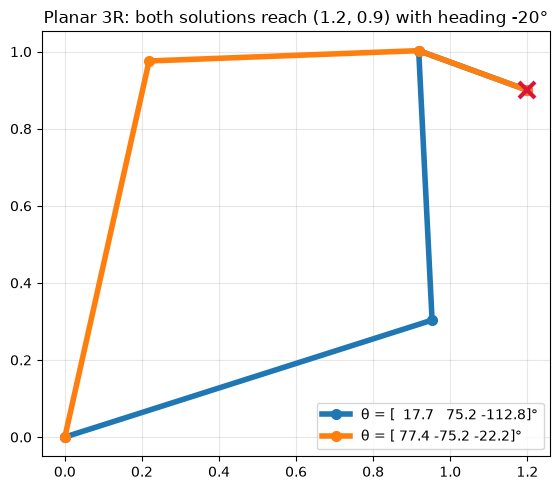

In [7]:
def ik_3R(x, y, phi, L1=1.0, L2=0.7, L3=0.3):
    # Planar 3R IK: all solutions (θ1, θ2, θ3) putting the tip at (x, y) with heading phi.
    wx, wy = x - L3 * np.cos(phi), y - L3 * np.sin(phi)      # 1. wrist point
    sols = []
    for th1, th2 in ik_2R_all(wx, wy, L1, L2):               # 2. 2R problem
        sols.append(wrap(np.array([th1, th2, phi - th1 - th2])))  # 3. last joint
    return sols


x_d, y_d, phi_d = 1.2, 0.9, np.radians(-20)
fig, ax = plt.subplots(figsize=(6.5, 5))
for q, col in zip(ik_3R(x_d, y_d, phi_d), ('tab:blue', 'tab:orange')):
    F = robot_3R.frames(q)
    pts = np.array([F[k][:2, 3] for k in ('0', '2', '3', 'e')])
    ax.plot(*pts.T, '-o', color=col, lw=4, ms=7, label=f'θ = {np.round(np.degrees(q), 1)}°')
    T = robot_3R.fk(q)
    print(f'θ = {np.round(np.degrees(q), 2)}°  ->  tip {np.round(T[:2, 3], 4)}, '
          f'heading {np.degrees(np.arctan2(T[1, 0], T[0, 0])):.2f}°')
ax.plot(x_d, y_d, 'x', color='crimson', ms=12, mew=3)
ax.set_aspect('equal'); ax.grid(alpha=0.3); ax.legend(loc='lower right')
ax.set_title('Planar 3R: both solutions reach (1.2, 0.9) with heading -20°')
plt.tight_layout(); plt.show()

### 7.3.2  SCARA

From Section 5.7 the SCARA gripper position and tool yaw are

$$\mathbf{o}_e = \begin{bmatrix}L_1c_1 + L_2c_{12}\\ L_1s_1 + L_2s_{12}\\ h - d_3 - d_e\end{bmatrix},\qquad
\varphi = \theta_1 + \theta_2 - \theta_4 .$$

The problem is already decoupled: the height depends only on the quill, the horizontal
position only on the 2R arm, and the yaw is a linear combination of joint angles. So:

1. $(\theta_1, \theta_2)$: 2R IK for $(x_d, y_d)$, two branches;
2. $d_3 = h - d_e - z_d$;
3. $\theta_4 = \theta_1 + \theta_2 - \varphi_d$.

In [8]:
def ik_scara(x, y, z, yaw, h=0.8, L1=0.8, L2=0.6, de=0.15):
    sols = []
    for th1, th2 in ik_2R_all(x, y, L1, L2):          # 1. horizontal 2R arm
        d3 = h - de - z                               # 2. quill
        th4 = wrap(th1 + th2 - yaw)                   # 3. tool roll
        sols.append(np.array([th1, th2, d3, th4]))
    return sols


x_d, y_d, z_d, yaw_d = 0.9, 0.5, 0.35, np.radians(30)
for q in ik_scara(x_d, y_d, z_d, yaw_d):
    T = robot_scara.fk(q)
    yaw = np.degrees(np.arctan2(T[1, 0], T[0, 0]))
    print(f'θ1 = {np.degrees(q[0]):7.2f}°, θ2 = {np.degrees(q[1]):7.2f}°, d3 = {q[2]:.3f} m, θ4 = {np.degrees(q[3]):7.2f}°'
          f'   ->  o_e = {np.round(T[:3, 3], 4)}, yaw = {yaw:.2f}°')

θ1 =   -6.51°, θ2 =   86.42°, d3 = 0.300 m, θ4 =   49.91°   ->  o_e = [0.9  0.5  0.35], yaw = 30.00°
θ1 =   64.62°, θ2 =  -86.42°, d3 = 0.300 m, θ4 =  -51.80°   ->  o_e = [0.9  0.5  0.35], yaw = 30.00°


### 7.3.3  Spherical wrist: orientation IK

In Section 5.5 the factors $\mathrm{Rot}_{x,-90^\circ}\,\mathrm{Rot}_{z,\theta_2}\,\mathrm{Rot}_{x,90^\circ}$
make a rotation about $y$, so the wrist orientation is the **ZYZ Euler angle** product
$\mathbf{R}_e^0 = \mathbf{R}_z(\theta_1)\,\mathbf{R}_y(\theta_2)\,\mathbf{R}_z(\theta_3)$:

$$\mathbf{R}_e^0 = \begin{bmatrix}
c_1c_2c_3 - s_1s_3 & -c_1c_2s_3 - s_1c_3 & c_1s_2\\
s_1c_2c_3 + c_1s_3 & -s_1c_2s_3 + c_1c_3 & s_1s_2\\
-s_2c_3 & s_2s_3 & c_2
\end{bmatrix}.$$

Given a desired $\mathbf{R}_d = [r_{ij}]$, read the angles off the last row and column:

- $r_{33} = c_2$ and $r_{13}^2 + r_{23}^2 = s_2^2$, so $\theta_2 = \mathrm{atan2}\!\left(\pm\sqrt{r_{13}^2 + r_{23}^2},\ r_{33}\right)$;
- if $s_2 \ne 0$: $\theta_1 = \mathrm{atan2}(r_{23}/s_2,\ r_{13}/s_2)$ and $\theta_3 = \mathrm{atan2}(r_{32}/s_2,\ -r_{31}/s_2)$.

Dividing by $s_2$ keeps the signs right. The two choices of sign give the two solutions
$(\theta_1, \theta_2, \theta_3)$ and $(\theta_1 + \pi, -\theta_2, \theta_3 + \pi)$, which
are the "wrist flip".

**At $s_2 = 0$** ($\theta_2 = 0$ or $\pi$) axes 1 and 3 line up: the gimbal-lock
singularity of Section 6.5.2. Then only $\theta_1 + \theta_3$ (or $\theta_1 - \theta_3$)
is determined, and there are infinitely many solutions. A controller keeps $\theta_1$ at
its current value and solves for $\theta_3$.

In [9]:
def ik_wrist(R, theta1_keep=0.0):
    # ZYZ orientation IK of the spherical wrist: list of (θ1, θ2, θ3).
    r = R
    s2 = np.hypot(r[0, 2], r[1, 2])
    if s2 < 1e-9:                                     # singular: axes 1 and 3 aligned
        th1 = theta1_keep
        if r[2, 2] > 0:                               # θ2 = 0: R = Rz(θ1 + θ3)
            return [np.array([th1, 0.0, wrap(np.arctan2(r[1, 0], r[0, 0]) - th1)])]
        return [np.array([th1, np.pi, wrap(th1 - np.arctan2(-r[1, 0], -r[0, 0]))])]   # θ2 = π: R = Rz(θ1 - θ3) Ry(π)
    sols = []
    for s in (s2, -s2):
        th2 = np.arctan2(s, r[2, 2])
        th1 = np.arctan2(r[1, 2] / s, r[0, 2] / s)
        th3 = np.arctan2(r[2, 1] / s, -r[2, 0] / s)
        sols.append(np.array([th1, th2, th3]))
    return sols


q_true = np.radians([40, 65, -110])
R_d = robot_wrist.fk(q_true)[:3, :3]
for q in ik_wrist(R_d):
    print(f'θ = {np.round(np.degrees(q), 2)}°   reproduces R_d: {np.allclose(robot_wrist.fk(q)[:3, :3], R_d)}')

R_sing = robot_wrist.fk(np.radians([25, 0, 35]))[:3, :3]            # gimbal lock: only θ1 + θ3 = 60° matters
for keep in (0, 25, 50):
    q = ik_wrist(R_sing, np.radians(keep))[0]
    print(f'singular, keep θ1 = {keep:2d}°:  θ = {np.round(np.degrees(q), 2)}°   reproduces R_d: '
          f'{np.allclose(robot_wrist.fk(q)[:3, :3], R_sing)}')

θ = [  40.   65. -110.]°   reproduces R_d: True
θ = [-140.  -65.   70.]°   reproduces R_d: True
singular, keep θ1 =  0°:  θ = [ 0.  0. 60.]°   reproduces R_d: True
singular, keep θ1 = 25°:  θ = [25.  0. 35.]°   reproduces R_d: True
singular, keep θ1 = 50°:  θ = [50.  0. 10.]°   reproduces R_d: True


### 7.3.4  Six-joint arms (overview)

For a 6-joint arm with a spherical wrist (the PUMA and many ABB, KUKA and Fanuc arms),
decoupling gives the complete solution:

1. wrist center $\mathbf{p}_w = \mathbf{p}_d - d_6\,\mathbf{R}_d\hat{\mathbf{z}}$;
2. $\theta_1,\theta_2,\theta_3$ from $\mathbf{p}_w$: shoulder left/right $\times$ elbow up/down, up to 4 solutions;
3. $\mathbf{R}_6^3 = (\mathbf{R}_3^0)^\top\mathbf{R}_d$, then the wrist angles as in Section 7.3.3: wrist flip, $\times2$.

That gives **up to 8 solutions**. The UR5e has no spherical wrist, but its three parallel
axes (2, 3, 4) also allow a closed form with up to 8 solutions. We won't derive it here;
in Section 7.6.3 we find its solutions numerically instead. Tools such as **IKFast**
(OpenRAVE) generate these closed-form solvers automatically from a robot model.

> **Key Takeaways — Section 7.3**
> - Planar 3R: wrist point $\mathbf{w} = \mathbf{p}_d - L_3(\cos\varphi_d, \sin\varphi_d)$, a 2R problem, then $\theta_3 = \varphi_d - \theta_1 - \theta_2$.
> - SCARA: 2R for $(x,y)$, $d_3$ from $z$, $\theta_4$ from yaw.
> - Spherical wrist: ZYZ angles from the last row and column of $\mathbf{R}_d$; two solutions, infinitely many at $s_2 = 0$.
> - 6-joint arms with a spherical wrist: decouple position and orientation, up to 8 solutions.

## 7.4  SO-ARM101 Analytical IK (Position + Pitch)

### 7.4.1  What can we ask the SO-ARM101 to do?

The SO-ARM101 has five arm joints, but a gripper pose has six numbers, so it **cannot**
reach an arbitrary pose. Its structure (Figure 7.3, the body frames of its MuJoCo model) tells us what it
*can* do:

- **Joint 1** (`shoulder_pan`) has a vertical axis and turns the whole arm.
- **Joints 2, 3, 4** (`shoulder_lift`, `elbow_flex`, `wrist_flex`) have **parallel,
  horizontal** axes, perpendicular to the arm. They move the gripper within one vertical
  plane, the **arm plane**.
- **Joint 5** (`wrist_roll`) turns about the gripper's approach axis $\mathbf{x}_e$ and spins the jaws.

So the approach axis $\mathbf{x}_e$ always lies in the arm plane. Its heading is set by
$\theta_1$, and its tilt is the **pitch** $\varphi$: the angle of $\mathbf{x}_e$ above
the horizontal. $\varphi = 0$ points straight out, and $\varphi = -90^\circ$ points straight
down (the top-down grasp). The IK task is therefore

> **Given the gripper position $\mathbf{p}_d = (x_d, y_d, z_d)$ and pitch $\varphi_d$, find
> $\theta_1,\dots,\theta_4$.** The roll $\theta_5$ is chosen directly, e.g. to line the jaws
> up with a block.

That is 4 equations for 4 unknowns.

<p align="center"><img src="Fig7-03_SO101_frames.png" width="560"></p>

<p align="center"><i>Figure 7.3 — SO-ARM101 frames and link offsets from the MuJoCo model. Joint i turns about the blue z-axis of frame {i}.</i></p>

### 7.4.2  The arm-plane geometry

We measure everything from the forward kinematics at home ($\boldsymbol\theta = \mathbf{0}$):

- The **pan axis** is vertical at $(x, y) = (x_p, 0)$ with $x_p = 0.0388$ m, and
  $\mathbf{z}_1 = -\mathbf{z}_0$ **points down**. A positive $\theta_1$ therefore turns the arm
  *clockwise* seen from above, and the heading $\psi$ of the arm plane (measured
  counterclockwise from $x_0$) is $\psi = -\theta_1$.
- In the arm plane we use coordinates $(r, z)$: $r$ is the horizontal distance from the pan
  axis and $z$ the height above the table (frame $\{0\}$).
- $S, E, W$ are the points where the axes of joints 2, 3, 4 pierce the arm plane, and $P$ is
  the gripper point $\mathbf{o}_e$ (the `gripperframe` site between the fingertips).

In [10]:
F0 = so101.frames(np.zeros(5))
x_p = F0['1'][0, 3]                                       # the pan axis is the vertical line x = x_p, y = 0


def to_plane(p, theta1=0.0):
    # (r, z) coordinates of point p in the arm plane, whose heading is ψ = -θ1
    psi = -theta1
    return np.array([(p[0] - x_p) * np.cos(psi) + p[1] * np.sin(psi), p[2]])


def heading(v):
    # Angle of the 2D vector v above the horizontal
    return np.arctan2(v[1], v[0])


S, E, W, P = [to_plane(F0[k][:3, 3]) for k in ('2', '3', '4', 'e')]
print('Approach axis x_e at home:', np.round(F0['e'][:3, 0], 6), '(horizontal, along x0)\n')

geo = SimpleNamespace(
    xp=x_p, S=S,
    L1=np.linalg.norm(E - S), L2=np.linalg.norm(W - E), L3=np.linalg.norm(P - W),   # |SE|, |EW|, |WP|
    alpha1=heading(E - S),                                  # heading of the upper arm SE at home
    gamma0=np.pi + heading(W - E) - heading(E - S),         # interior angle S-E-W at home (elbow bend at θ3 = 0)
    delta=heading(P - W))                                   # heading of WP at home, where x_e is horizontal

print(f'x_p    = {geo.xp:.5f} m      pan axis position')
print(f'S      = ({geo.S[0]:.5f}, {geo.S[1]:.5f}) m   shoulder-lift axis in the arm plane (r, z)')
print(f'L1     = {geo.L1:.5f} m      |SE|, upper arm')
print(f'L2     = {geo.L2:.5f} m      |EW|, forearm')
print(f'L3     = {geo.L3:.5f} m      |WP|, wrist to gripper point')
print(f'α1     = {np.degrees(geo.alpha1):.3f}°     heading of SE at home')
print(f'γ0     = {np.degrees(geo.gamma0):.3f}°    elbow angle S-E-W at home')
print(f'δ      = {np.degrees(geo.delta):.3f}°     tilt of WP from the approach axis x_e')

Approach axis x_e at home: [ 1. -0.  0.] (horizontal, along x0)

x_p    = 0.03884 m      pan axis position
S      = (0.03040, 0.11660) m   shoulder-lift axis in the arm plane (r, z)
L1     = 0.11600 m      |SE|, upper arm
L2     = 0.13500 m      |EW|, forearm
L3     = 0.15942 m      |WP|, wrist to gripper point
α1     = 76.032°     heading of SE at home
γ0     = 106.175°    elbow angle S-E-W at home
δ      = -2.841°     tilt of WP from the approach axis x_e


<p align="center"><img src="Fig7-04_SO101_geometry.png" width="980"></p>

<p align="center"><i>Figure 7.4 — SO-ARM101 IK geometry. (a) Top view: θ<sub>1</sub> aims the arm plane at the target. (b) The arm plane: θ<sub>2</sub>, θ<sub>3</sub>, θ<sub>4</sub> are measured from the home pose (faded), each from where its link points with that joint at zero (dashed); α<sub>1</sub> and γ<sub>0</sub> are read off the home pose. (c) Solving: back off from P<sub>d</sub> to the wrist point W, then solve the triangle S, E, W.</i></p>

**Measure the servo angles from home.** The servo angles are rotations of the links about
joint axes 2, 3, 4, so we draw them directly in the arm plane (Figure 7.4(b)):

- **Direction.** At home the axes of joints 2, 3, 4 point along $+y_0$. In Figure 7.4(b)
  (r to the right, z up) that is *into the page*, and a right-handed rotation about an
  into-the-page axis is **clockwise** in the picture. So a positive $\theta$ turns its link
  *down*.
- **Zero.** Each angle is measured from where its link points when *that* joint is at zero
  (the dashed lines): $\theta_2$ from the home upper arm, $\theta_3$ from the forearm carried
  along rigidly by the upper arm, and $\theta_4$ from the last link carried along by the forearm.

Two constants of the home pose, printed above, pin down the picture: $\alpha_1$, the angle
of the upper arm $SE$ above the horizontal, and $\gamma_0$, the interior angle $S$–$E$–$W$
(how bent the elbow is when $\theta_3 = 0$).

**Pitch.** $P$ sits slightly below the approach axis through $W$, so the last link $WP$ is
tilted by a fixed angle $\delta$ from $\mathbf{x}_e$ (at home $\mathbf{x}_e$ is horizontal,
so $\delta$ is just the home heading of $WP$). All three joints turn $\mathbf{x}_e$ clockwise,
so

$$\varphi = -(\theta_2 + \theta_3 + \theta_4),$$

and the last link $WP$ points at $\varphi + \delta$ above the horizontal.

(This is the planar 3R arm of Section 7.3.1 with its base at $S$; measuring the angles from
home lets us solve for the servo angles directly.) The cell below checks this picture
against the full 3D forward kinematics: it rebuilds $P$ and $\varphi$ from $\theta_2, \theta_3, \theta_4$
in the arm plane and compares them with `so101.fk`.

> **Sideways offsets.** $S$, $E$, $W$ sit 18.3 mm to the side of the pan axis, but that
> offset is *along* the joint axes and does not change the planar geometry. The wrist
> bracket brings the gripper back: with $\theta_5 = 0$, $P$ is only 0.011 mm from the plane
> through the pan axis. We ignore those 0.011 mm until Section 7.4.5.
> (A chain that rounds the `wrist_roll` rotation to clean 90° turns drops a 2.79° twist
> in the model's quaternion; it puts $P$ 0.4 mm off the plane, and the IK below then misses
> by about 0.4 mm instead of 0.01 mm.)

In [11]:
def link_headings(t2, t3, t4, delta=geo.delta):
    # Planar FK helper: angles of SE, EW, WP above the horizontal (works on arrays too).
    # SE starts at α1 and turns clockwise by θ2; EW is bent (180° - γ0) further down at home, plus θ3;
    # WP points at φ + δ with φ = -(θ2 + θ3 + θ4).
    h1 = geo.alpha1 - t2
    h2 = h1 - (np.pi - geo.gamma0) - t3
    h3 = delta - (t2 + t3 + t4)
    return h1, h2, h3


def so101_planar_fk(q):
    # Gripper point P = (r, z) in the arm plane, and pitch φ, from θ2, θ3, θ4
    h = link_headings(*q[1:4])
    P = geo.S + sum(L * np.array([np.cos(hi), np.sin(hi)]) for L, hi in zip((geo.L1, geo.L2, geo.L3), h))
    return P, -(q[1] + q[2] + q[3])


def pitch(T):
    # Pitch of the approach axis x_e above the horizontal
    return np.arcsin(np.clip(T[2, 0], -1, 1))


rng = np.random.default_rng(1)
err_P, err_phi = 0, 0
for _ in range(500):
    q = rng.uniform(so101.lo, so101.hi); q[4] = 0.0
    T = so101.fk(q)
    P_plane, phi = so101_planar_fk(q)
    err_P = max(err_P, np.abs(P_plane - to_plane(T[:3, 3], q[0])).max())
    if abs(phi) < np.pi / 2:
        err_phi = max(err_phi, abs(phi - pitch(T)))
print(f'Planar FK vs. 3D FK, 500 random poses: max |ΔP| = {err_P:.1e} m, max |Δφ| = {err_phi:.1e} rad')

Planar FK vs. 3D FK, 500 random poses: max |ΔP| = 1.7e-16 m, max |Δφ| = 2.0e-13 rad


### 7.4.3  The solution, step by step

Given $\mathbf{p}_d = (x_d, y_d, z_d)$, the pitch $\varphi_d$ and the roll $\theta_5$
(Figure 7.4(c)):

**Step 1, aim the arm plane ($\theta_1$).**
$\psi = \mathrm{atan2}(y_d,\ x_d - x_p)$, $\ \theta_1 = -\psi$, and the target in the arm
plane is $P_d = (r, z_d)$ with $r = \sqrt{(x_d - x_p)^2 + y_d^2}$.

**Step 2, back off to the wrist point.** The last link must point at
$\varphi_d + \delta$ above the horizontal, so

$$W = P_d - L_3\big(\cos(\varphi_d + \delta),\ \sin(\varphi_d + \delta)\big),\qquad D = |W - S| .$$

What is left is the triangle $S, E, W$ with sides $L_1$, $L_2$ and $D$.

**Step 3, elbow ($\theta_3$).** The law of cosines (Section 7.2.2) gives the interior angle
at $E$:

$$\gamma = \mathrm{acos}\frac{L_1^2 + L_2^2 - D^2}{2L_1L_2}.$$

If the fraction is outside $[-1, 1]$, $W$ is out of reach. A positive $\theta_3$ bends the
elbow further, closing the triangle from its home value $\gamma_0$, so
$\ \theta_3 = \gamma_0 - \gamma$.

**Step 4, shoulder ($\theta_2$).** The upper arm makes the angle
$\sigma = \mathrm{acos}\big((L_1^2 + D^2 - L_2^2)/(2L_1D)\big)$ with the line $SW$, whose
angle above the horizontal is $\psi_{SW} = \mathrm{atan2}(W - S)$. With the elbow up, $SE$ lies
above $SW$, so the upper arm points at $\psi_{SW} + \sigma$. At home it pointed at $\alpha_1$,
and $\theta_2$ is how far it has turned clockwise since: $\ \theta_2 = \alpha_1 - (\psi_{SW} + \sigma)$.

**Step 5, wrist ($\theta_4$).** From the pitch: $\ \theta_4 = -\varphi_d - \theta_2 - \theta_3$.

**Step 6, roll and limits.** $\theta_5$ is the roll you want. Check all five joints against their limits.

**Elbow down** is the mirror-image triangle, with $E$ below $SW$:
$\theta_2 = \alpha_1 - (\psi_{SW} - \sigma)$ and $\theta_3 = \gamma_0 + \gamma - 360^\circ$.

Note that $\theta_3 = \gamma_0 - \gamma$ depends only on the distance $D = |SW|$: when the arm
is straight ($\gamma = 180^\circ$) the elbow servo reads $\gamma_0 - 180^\circ = -73.8^\circ$.

In [12]:
def arm_plane_ik(r, z, phi_d, elbow='up', L3=geo.L3, delta=geo.delta):
    # θ2, θ3, θ4 from the triangle S, E, W in the arm plane, or None if out of reach
    W = np.array([r, z]) - L3 * np.array([np.cos(phi_d + delta), np.sin(phi_d + delta)])   # Step 2
    D = np.linalg.norm(W - geo.S)
    c = (geo.L1**2 + geo.L2**2 - D**2) / (2 * geo.L1 * geo.L2)
    if abs(c) > 1:
        return None
    gamma = np.arccos(c)                                                                      # Step 3
    sigma = np.arccos(np.clip((geo.L1**2 + D**2 - geo.L2**2) / (2 * geo.L1 * D), -1, 1))     # Step 4
    psi_sw = heading(W - geo.S)
    if elbow == 'up':
        theta3, theta2 = geo.gamma0 - gamma, geo.alpha1 - (psi_sw + sigma)
    else:
        theta3, theta2 = geo.gamma0 + gamma - 2 * np.pi, geo.alpha1 - (psi_sw - sigma)
    theta4 = -phi_d - theta2 - theta3                                                         # Step 5
    return np.array([theta2, theta3, theta4])


def so101_ik(p_d, phi_d, theta5=0.0, elbow='up'):
    # Analytical position + pitch IK of the SO-ARM101.
    # Returns the joint vector (rad), or None if the wrist point is out of reach.
    x, y, z = p_d
    # Step 1 - aim the arm plane at the target
    theta1 = -np.arctan2(y, x - geo.xp)
    r = np.hypot(x - geo.xp, y)
    # Steps 2 to 5 - the triangle S, E, W in the arm plane
    t = arm_plane_ik(r, z, phi_d, elbow)
    return None if t is None else wrap(np.array([theta1, *t, theta5]))


def report_so101(q, p_d=None, phi_d=None):
    names = [j[0] for j in so101.joints]
    for name, qi, lo, hi in zip(names, q, so101.lo, so101.hi):
        flag = '' if lo - 1e-9 <= qi <= hi + 1e-9 else f'   <-- outside [{np.degrees(lo):.1f}, {np.degrees(hi):.1f}]°'
        print(f'    {name:14s} {np.degrees(qi):8.2f}°{flag}')
    T = so101.fk(q)
    msg = f'    FK: p = {np.round(T[:3, 3], 5)} m, pitch = {np.degrees(pitch(T)):.2f}°'
    if p_d is not None:
        msg += f'   (position error {np.linalg.norm(T[:3, 3] - p_d) * 1000:.4f} mm)'
    print(msg)


p_d, phi_d = np.array([0.25, 0.05, 0.02]), np.radians(-90)       # top-down grasp
q = so101_ik(p_d, phi_d)
print(f'Target p_d = {p_d} m, pitch = -90°:')
report_so101(q, p_d)

Target p_d = [0.25 0.05 0.02] m, pitch = -90°:
    shoulder_pan     -13.32°
    shoulder_lift     19.46°
    elbow_flex        -2.59°
    wrist_flex        73.13°
    wrist_roll         0.00°
    FK: p = [0.25 0.05 0.02] m, pitch = -90.00°   (position error 0.0112 mm)


The error of about 0.01 mm is the sideways offset we ignored; Section 7.4.5 removes it.
Let's test the solver on many random targets. We generate each target from a random joint
vector (so we know it is reachable), solve, and compare poses rather than joints, because
the random joint vector may be on a different branch.

In [13]:
rng = np.random.default_rng(2)
errs, n_ok = [], 0
for _ in range(2000):
    q_rand = rng.uniform(so101.lo, so101.hi); q_rand[4] = 0.0
    T = so101.fk(q_rand)
    if abs(q_rand[1] + q_rand[2] + q_rand[3]) > np.pi / 2:      # keep |pitch| < 90°, where pitch() is unambiguous
        continue
    for elbow in ('up', 'down'):
        q = so101_ik(T[:3, 3], pitch(T), elbow=elbow)
        Tq = so101.fk(q)
        errs.append([np.linalg.norm(Tq[:3, 3] - T[:3, 3]), abs(pitch(Tq) - pitch(T))])
errs = np.array(errs)
print(f'{len(errs)} IK solves: max position error {errs[:, 0].max() * 1000:.4f} mm, '
      f'max pitch error {np.degrees(errs[:, 1].max()):.1e}°')

2470 IK solves: max position error 0.0112 mm, max pitch error 7.2e-12°


### 7.4.4  Branches, joint limits, and where top-down grasps are possible

Mathematically there are up to **four** solutions: elbow up or down, and the arm facing the
target or reaching backward over its own base ($\theta_1 \pm 180^\circ$). The joint limits
remove nearly all of them:

- **Elbow down** needs $\theta_3 = \gamma_0 + \gamma - 360^\circ \ge -96.8^\circ$ (the elbow
  limit), so $\gamma > 157^\circ$: only an almost straight arm.
- **Reaching backward** bends the shoulder far past its $\pm100^\circ$ limit. In thousands of
  random targets on the table, no backward solution was within the limits.

So in practice the SO-ARM101 has **one usable solution: elbow up, facing the target.**
That is why `so101_ik` defaults to `elbow='up'`.

In [14]:
p_d, phi_d = np.array([0.22, -0.06, 0.03]), np.radians(-90)
for elbow in ('up', 'down'):
    q = so101_ik(p_d, phi_d, elbow=elbow)
    print(f'elbow {elbow}:  within limits = {so101.within_limits(q)}')
    report_so101(q, p_d)

elbow up:  within limits = True
    shoulder_pan      18.32°
    shoulder_lift      5.39°
    elbow_flex        12.64°
    wrist_flex        71.97°
    wrist_roll         0.00°
    FK: p = [ 0.22 -0.06  0.03] m, pitch = -90.00°   (position error 0.0112 mm)
elbow down:  within limits = False
    shoulder_pan      18.32°
    shoulder_lift    100.00°
    elbow_flex      -160.29°   <-- outside [-96.8, 96.8]°
    wrist_flex       150.29°   <-- outside [-95.0, 95.0]°
    wrist_roll         0.00°
    FK: p = [ 0.22 -0.06  0.03] m, pitch = -90.00°   (position error 0.0112 mm)


**Where can the gripper point straight down?** Sweep $\theta_2$ and $\theta_3$ over their
ranges, set $\theta_4 = 90^\circ - \theta_2 - \theta_3$ so that $\varphi = -90^\circ$, keep
only $\theta_4$ within its limit, and plot the gripper point with the planar FK. The light
background shows every point the arm can reach with *some* pitch.

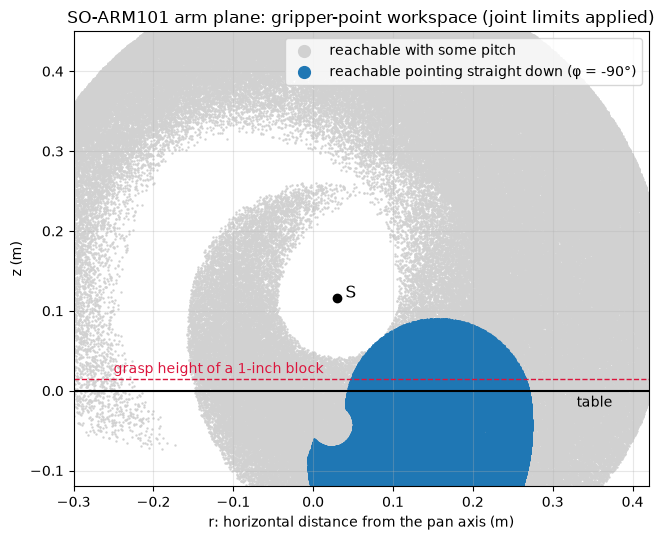

Top-down grasp at z = 0.015 m possible for r from 0.048 to 0.265 m (world x from 0.086 to 0.304 m when y = 0)


In [15]:
def planar_points(t2, t3, t4):
    # so101_planar_fk for whole arrays of joint angles at once
    h1, h2, h3 = link_headings(t2, t3, t4)
    r = geo.S[0] + geo.L1 * np.cos(h1) + geo.L2 * np.cos(h2) + geo.L3 * np.cos(h3)
    z = geo.S[1] + geo.L1 * np.sin(h1) + geo.L2 * np.sin(h2) + geo.L3 * np.sin(h3)
    return np.column_stack([r, z])


rng = np.random.default_rng(5)
Q = rng.uniform(so101.lo[1:4], so101.hi[1:4], size=(300_000, 3))         # random θ2, θ3, θ4 within limits
P_any = planar_points(*Q.T)
t2, t3 = rng.uniform(so101.lo[1:3], so101.hi[1:3], size=(300_000, 2)).T
t4 = np.pi / 2 - t2 - t3                                                  # pitch = -90°
ok = (t4 >= so101.lo[3]) & (t4 <= so101.hi[3])
P_down = planar_points(t2[ok], t3[ok], t4[ok])

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(*P_any.T, s=0.5, color='0.82', rasterized=True, label='reachable with some pitch')
ax.scatter(*P_down.T, s=0.5, color='tab:blue', rasterized=True, label='reachable pointing straight down (φ = -90°)')
ax.axhline(0, color='k', lw=1.5); ax.text(0.33, -0.02, 'table', fontsize=10)
ax.axhline(0.015, color='crimson', ls='--', lw=1); ax.text(-0.25, 0.022, 'grasp height of a 1-inch block', color='crimson', fontsize=10)
ax.plot(*geo.S, 'ko'); ax.text(geo.S[0] + 0.01, geo.S[1], 'S', fontsize=12)
ax.set_xlabel('r: horizontal distance from the pan axis (m)'); ax.set_ylabel('z (m)')
ax.set_aspect('equal'); ax.grid(alpha=0.3); ax.legend(loc='upper right', markerscale=12)
ax.set_xlim(-0.3, 0.42); ax.set_ylim(-0.12, 0.45)
ax.set_title('SO-ARM101 arm plane: gripper-point workspace (joint limits applied)')
plt.tight_layout(); plt.show()

band = P_down[np.abs(P_down[:, 1] - 0.015) < 0.002]
print(f'Top-down grasp at z = 0.015 m possible for r from {band[:, 0].min():.3f} to {band[:, 0].max():.3f} m '
      f'(world x from {band[:, 0].min() + geo.xp:.3f} to {band[:, 0].max() + geo.xp:.3f} m when y = 0)')

Below the table the region is mathematically reachable but physically blocked; IK knows
nothing about the table, so your code has to. When a target is too far for a top-down
grasp, a common fix is to **tilt the approach**: try $\varphi = -90^\circ, -85^\circ,
\dots$ and take the first pitch whose solution is within the limits.

In [16]:
def so101_ik_tilt(p_d, theta5=0.0, phis_deg=np.arange(-90, 1, 5)):
    # Try pitches from straight down toward horizontal; return the first solution within limits.
    for phi in phis_deg:
        q = so101_ik(p_d, np.radians(phi), theta5)
        if q is not None and so101.within_limits(q):
            return q, phi
    return None, None


print(f'{"target x (m)":>12}  {"pitch used":>10}   joint angles (°)')
for x in (0.15, 0.25, 0.30, 0.33, 0.36, 0.40):
    q, phi = so101_ik_tilt(np.array([x, 0.0, 0.015]))
    print(f'{x:12.2f}  ' + ('   no solution' if q is None else f'{phi:9d}°   {np.round(np.degrees(q[:4]), 1)}'))

target x (m)  pitch used   joint angles (°)
        0.15        -90°   [  0.  -31.8  57.1  64.8]
        0.25        -90°   [ 0.  17.3  2.8 69.9]
        0.30        -90°   [  0.   49.5 -49.8  90.3]
        0.33        -80°   [  0.   52.4 -54.5  82.1]
        0.36        -70°   [  0.   56.4 -59.1  72.8]
        0.40        -55°   [  0.   59.  -56.5  52.5]


**Explore it.** The sliders set the target and pitch, and the arm is drawn from `so101_ik`.
Joints outside their limits are flagged. Try pushing the target outward with a top-down
pitch and watch $\theta_4$ run into its limit, then tilt the pitch.

In [ ]:
def explore_so101_ik():
    def _view(x=0.25, y=0.05, z=0.03, pitch_deg=-90, roll_deg=0, elbow='up'):
        p_d = np.array([x, y, z])
        q = so101_ik(p_d, np.radians(pitch_deg), np.radians(roll_deg), elbow)
        fig = plt.figure(figsize=(7, 6.5))
        ax = fig.add_subplot(111, projection='3d')
        ax.scatter(*p_d, marker='x', color='crimson', s=120, linewidths=3)
        if q is None:
            title = 'wrist point out of reach'
        else:
            plot_robot(ax, so101, q, scale=0.04)
            title = 'within joint limits' if so101.within_limits(q) else 'VIOLATES joint limits'
        setup_3d(ax, title=f'SO-ARM101 analytical IK: {title}', **view_so101)
        plt.show()
        if q is not None:
            report_so101(q, p_d)

    interact(_view,
             x=FloatSlider(value=0.25, min=0.0, max=0.45, step=0.005, description='x_d (m)'),
             y=FloatSlider(value=0.05, min=-0.3, max=0.3, step=0.005, description='y_d (m)'),
             z=FloatSlider(value=0.03, min=-0.05, max=0.35, step=0.005, description='z_d (m)'),
             pitch_deg=FloatSlider(value=-90, min=-90, max=90, step=1, description='pitch (°)'),
             roll_deg=FloatSlider(value=0, min=-150, max=150, step=5, description='θ₅ roll (°)'),
             elbow=Dropdown(options=['up', 'down'], value='up', description='elbow'))


explore_so101_ik()

interactive(children=(FloatSlider(value=0.25, description='x_d (m)', max=0.45, step=0.005), FloatSlider(value=…

### 7.4.5  Exact solution for any wrist roll (optional)

The gripper point lies $|c| = 7.9$ mm off the roll axis, so rolling $\theta_5$ swings it on a
small circle: up to 7.9 mm **sideways**, out of the arm plane, and it also changes the
in-plane offset. The problem stays solvable in closed form, and it uses the equation of
Section 7.2.3.

**Tool offsets for a given roll.** Joints 2 to 4 only rotate frame $\{4\}$ about the
sideways axis, so the gripper point seen from frame $\{4\}$ depends on $\theta_5$ alone:
$\mathbf{p}_e^4(\theta_5) = $ origin of $\mathbf{T}_5^4(\theta_5)\,\mathbf{T}_e^5$. At home,
$-\mathbf{y}_4$ is the approach axis, $-\mathbf{x}_4$ is "up" across it, and $\mathbf{z}_4$
is sideways. So

$$a(\theta_5) = -p_y,\qquad c(\theta_5) = -p_x,\qquad d(\theta_5) = d_4 + p_z,$$

where $d_4 = -18.3$ mm is the sideways offset of $\mathbf{o}_4$ from the plane through the
pan axis. In the arm plane, the last link becomes $L_3(\theta_5) = \sqrt{a^2 + c^2}$ with
tilt $\delta(\theta_5) = \mathrm{atan2}(c, a)$ from $\mathbf{x}_e$.

**Step 1 with a sideways offset.** Write the target relative to the pan axis as
$X = x_d - x_p$, $Y = y_d$. If the arm plane has heading $\psi$, the gripper point is $r$
along the plane and $d$ sideways:
$(X, Y) = r\,(\cos\psi, \sin\psi) + d\,(-\sin\psi, \cos\psi)$. Taking the sideways component
gives

$$-X\sin\psi + Y\cos\psi = d ,$$

which is exactly $a\cos\psi + b\sin\psi = c$ with $(a, b, c) = (Y, -X, d)$. Of its two roots,
one faces the target ($r > 0$) and the other faces away. The forward-facing one is

$$r = \sqrt{X^2 + Y^2 - d^2},\qquad \psi = \mathrm{atan2}(Y, X) - \mathrm{atan2}(d, r),\qquad \theta_1 = -\psi .$$

Steps 2 to 6 are unchanged, using $L_3(\theta_5)$ and $\delta(\theta_5)$ in Step 2.

In [18]:
d4 = F0['4'][1, 3]                     # sideways offset of o_4 (the joint axes point along +y0 at home)


def tool_offsets(theta5):
    # (a, c, d) of the gripper point for wrist roll θ5, from its position in frame {4}
    p = (so101.home[4] @ Rot('z', theta5) @ SO101_Te5)[:3, 3]
    return -p[1], -p[0], d4 + p[2]


def so101_ik_exact(p_d, phi_d, theta5=0.0, elbow='up'):
    a, c, d = tool_offsets(theta5)
    X, Y, z = p_d[0] - geo.xp, p_d[1], p_d[2]
    if X**2 + Y**2 < d**2:
        return None
    # Step 1 - aim the arm plane, now with a sideways offset d
    r = np.sqrt(X**2 + Y**2 - d**2)
    psi = np.arctan2(Y, X) - np.arctan2(d, r)
    # Steps 2 to 5 - exactly as before, with the last link L3(θ5), δ(θ5) of this roll
    t = arm_plane_ik(r, z, phi_d, elbow, L3=np.hypot(a, c), delta=np.arctan2(c, a))
    return None if t is None else wrap(np.array([-psi, *t, theta5]))


for t5 in (0, 45, 90):
    a, c, d = tool_offsets(np.radians(t5))
    print(f'θ5 = {t5:3d}°:  a = {a * 1000:7.3f} mm,  c = {c * 1000:6.3f} mm,  d = {d * 1000:6.3f} mm')

rng = np.random.default_rng(3)
worst = 0
for _ in range(2000):
    q_rand = rng.uniform(so101.lo, so101.hi)
    if abs(q_rand[1] + q_rand[2] + q_rand[3]) > np.pi / 2:
        continue
    T = so101.fk(q_rand)
    for elbow in ('up', 'down'):
        q = so101_ik_exact(T[:3, 3], pitch(T), q_rand[4], elbow)
        worst = max(worst, np.linalg.norm(so101.fk(q)[:3, 3] - T[:3, 3]))
print(f'\nExact IK, random targets and random roll: max position error = {worst:.1e} m')

X, Y = 0.20, 0.07
a_, c_, d = tool_offsets(np.radians(90))
print('Roots of -X sinψ + Y cosψ = d:', np.round(np.degrees(solve_acos_bsin(Y, -X, d)), 3),
      '°;  forward-facing root used above:',
      np.round(np.degrees(np.arctan2(Y, X) - np.arctan2(d, np.sqrt(X**2 + Y**2 - d**2))), 3), '°')

θ5 =   0°:  a = 159.227 mm,  c = -7.901 mm,  d = -0.011 mm
θ5 =  45°:  a = 159.227 mm,  c = -5.705 mm,  d = -5.647 mm
θ5 =  90°:  a = 159.227 mm,  c = -0.167 mm,  d = -8.079 mm

Exact IK, random targets and random roll: max position error = 3.5e-14 m
Roots of -X sinψ + Y cosψ = d: [  21.475 -162.895] °;  forward-facing root used above: 21.475 °


> **Key Takeaways — Section 7.4**
> - The SO-ARM101 has 5 joints, so we ask for position + pitch (4 numbers) and set the roll $\theta_5$ directly.
> - Structure: the pan joint aims the arm plane; joints 2 to 4 swing the links $SE$, $EW$, $WP$ in it. Measure $\theta_2, \theta_3, \theta_4$ from the home pose (positive = clockwise in Figure 7.4), using the home constants $\alpha_1$, $\gamma_0$, $\delta$; the pitch is $\varphi = -(\theta_2+\theta_3+\theta_4)$.
> - Recipe: $\theta_1 = -\mathrm{atan2}(y_d, x_d - x_p)$; wrist point $W = P_d - L_3\mathbf{u}(\varphi_d + \delta)$; law of cosines on $S, E, W$: $\theta_3 = \gamma_0 - \gamma$, $\theta_2 = \alpha_1 - (\psi_{SW} + \sigma)$; then $\theta_4 = -\varphi_d - \theta_2 - \theta_3$.
> - Joint limits leave one usable branch (elbow up, facing the target). A top-down grasp at table height works only in a band of $r$; beyond it, tilt the pitch.
> - With $\theta_5 \neq 0$ the gripper point moves sideways, and $\theta_1$ comes from $a\cos\psi + b\sin\psi = c$.

## 7.5  Numerical IK

Analytical IK needs a derivation for each robot and a robot with convenient structure.
For anything else (offset wrists, 7-joint arms, humanoids, or tasks that mix several goals)
we solve numerically. All we need is the forward kinematics and the Jacobian, and we
already have both.

### 7.5.1  IK as root finding: Newton–Raphson

Write the forward kinematics as a function $\mathbf{f}$ of the joint angles:

$$\mathbf{Y}_d = \mathbf{f}(\boldsymbol\theta_d),\qquad
\mathbf{Y}_d = \begin{bmatrix} \mathbf{p}_d \\ \mathbf{o}_d \end{bmatrix},\quad
\mathbf{p}_d = \begin{bmatrix} x \\ y \\ z \end{bmatrix}\ \text{(position)},\quad
\mathbf{o}_d = \begin{bmatrix} \phi \\ \vartheta \\ \psi \end{bmatrix}\ \text{(orientation)}$$

where $\boldsymbol\theta_d$ are the joint angles. $\mathbf{Y}_d$ can also hold only part of
the pose (position only; position + pitch), with $m$ entries in general.

**Inverse kinematics:** given $\mathbf{Y}_d$, solve for the corresponding $\boldsymbol\theta_d$.
Move everything to one side and define

$$\mathbf{g}(\boldsymbol\theta) = \mathbf{Y}_d - \mathbf{f}(\boldsymbol\theta) = \mathbf{0},$$

a set of **nonlinear equations** in $\boldsymbol\theta$. The vector $\mathbf{g}$ is the error
between where we want the gripper and where joints $\boldsymbol\theta$ put it, and the IK
solution is its root: $\mathbf{g}(\boldsymbol\theta_d) = \mathbf{0}$.

Let $\boldsymbol\theta^0$ be an **initial guess** close to $\boldsymbol\theta_d$. Expanding
$\mathbf{f}$ in a Taylor series about $\boldsymbol\theta^0$,

$$\mathbf{Y}_d = \mathbf{f}(\boldsymbol\theta_d)
= \mathbf{f}(\boldsymbol\theta^0) + \underbrace{\left.\frac{\partial\mathbf{f}}{\partial\boldsymbol\theta}\right|_{\boldsymbol\theta^0}}_{\mathbf{J}(\boldsymbol\theta^0)}(\boldsymbol\theta_d - \boldsymbol\theta^0) + \text{higher-order terms}.$$

The derivative is the Jacobian $\mathbf{J}(\boldsymbol\theta^0)$ of Chapter 6. Dropping the
higher-order terms and solving for $\boldsymbol\theta_d$,

$$\boldsymbol\theta_d \approx \boldsymbol\theta^0 + \mathbf{J}^{-1}(\boldsymbol\theta^0)\left[\mathbf{Y}_d - \mathbf{f}(\boldsymbol\theta^0)\right].$$

Because the higher-order terms were dropped, this is only a better guess, not the answer.
Repeating it gives **Newton's method** (Section 6.6.2), the iterative rule at step $k$:

$$\boxed{\boldsymbol\theta^k = \boldsymbol\theta^{k-1} + \mathbf{J}^{-1}(\boldsymbol\theta^{k-1})\left[\mathbf{Y}_d - \mathbf{f}(\boldsymbol\theta^{k-1})\right]}$$

In the rest of this section we write the step as $\Delta\boldsymbol\theta = \boldsymbol\theta^k - \boldsymbol\theta^{k-1}$
and the current error as $\mathbf{e} = \mathbf{g}(\boldsymbol\theta^{k-1}) = \mathbf{Y}_d - \mathbf{f}(\boldsymbol\theta^{k-1})$,
so each Newton step solves $\mathbf{J}\,\Delta\boldsymbol\theta = \mathbf{e}$.

Close to a solution it converges **quadratically**: the number of correct digits roughly
doubles every iteration. But it

- needs a square, invertible $\mathbf{J}$ ($m = n$, away from singularities);
- can jump far away or diverge from a poor initial guess;
- has nothing sensible to converge to when the target is unreachable.

**The one-joint version.** Take a unit link turning about a fixed joint, and let the task be
the height of its tip. Each piece of the general method becomes a scalar:

| General | One joint |
|---|---|
| forward kinematics $\mathbf{f}(\boldsymbol\theta)$ | $f(\theta) = \sin\theta$ |
| target $\mathbf{Y}_d$ | $Y_d = h_d$ |
| $\mathbf{g}(\boldsymbol\theta) = \mathbf{Y}_d - \mathbf{f}(\boldsymbol\theta)$ | $g(\theta) = h_d - \sin\theta$ |
| Jacobian $\mathbf{J} = \partial\mathbf{f}/\partial\boldsymbol\theta$ | $J(\theta) = \dfrac{df}{d\theta} = \cos\theta$ |
| Taylor expansion $\mathbf{Y}_d \approx \mathbf{f}(\boldsymbol\theta^{k-1}) + \mathbf{J}(\boldsymbol\theta^{k-1})(\boldsymbol\theta^k - \boldsymbol\theta^{k-1})$ | $h_d \approx \sin\theta^{k-1} + \cos\theta^{k-1}\,(\theta^k - \theta^{k-1})$ |
| Newton rule $\boldsymbol\theta^k = \boldsymbol\theta^{k-1} + \mathbf{J}^{-1}\left[\mathbf{Y}_d - \mathbf{f}(\boldsymbol\theta^{k-1})\right]$ | $\theta^k = \theta^{k-1} + \dfrac{h_d - \sin\theta^{k-1}}{\cos\theta^{k-1}}$ |

so the iteration is

$$\boxed{\theta^k = \theta^{k-1} + \frac{h_d - \sin\theta^{k-1}}{\cos\theta^{k-1}}}$$

Geometrically, $\sin\theta^{k-1} + \cos\theta^{k-1}\,(\theta - \theta^{k-1})$ is the tangent
line to $f(\theta)$ at $\theta^{k-1}$, and $\theta^k$ is where that line reaches the height $h_d$.

**Reachable target**, $h_d = 0.8$, starting from $\theta^0 = 0.2$ rad:

| $k$ | $\theta^k$ (rad) | $g(\theta^k) = 0.8 - \sin\theta^k$ | $J(\theta^k) = \cos\theta^k$ | $\theta^{k+1} - \theta^k = g / J$ |
|---|---|---|---|---|
| 0 | 0.2000 | 0.6013 | 0.9801 | 0.6136 |
| 1 | 0.8136 | 0.0733 | 0.6869 | 0.1067 |
| 2 | 0.9202 | 0.0043 | 0.6056 | 0.0070 |
| 3 | 0.9273 | $\approx 2\times10^{-5}$ | 0.6000 | $\approx 3\times10^{-5}$ |

The error shrinks $0.60 \to 0.073 \to 0.0043 \to 0.00002$: each error is roughly the square
of the one before, which is quadratic convergence. The limit is the exact solution
$\theta^* = \arcsin 0.8 = 0.9273$ rad.

**Unreachable target**, $h_d = 1.2 > 1$: $g(\theta) = 1.2 - \sin\theta \ge 0.2$ for every
$\theta$, so there is no root to find. The tangent steps overshoot $\theta = \pi/2$, where
$J = \cos\theta$ changes sign, and the iteration bounces from side to side
($0.20 \to 1.22 \to 1.98 \to 1.27 \to 2.11 \to \cdots$). Near $\theta = \pi/2$ the
Jacobian $\cos\theta \to 0$ and a single step $g/\cos\theta$ can be enormous: the one-joint
picture of a singularity.

The figure shows both cases: each step follows the tangent line to the target height.

h_d = 0.8 (reachable):   θ_k = [0.2    0.8136 0.9202 0.9273 0.9273 0.9273]
h_d = 1.2 (unreachable): θ_k = [0.2   1.222 1.983 1.274 2.108 1.442 3.065 1.938]


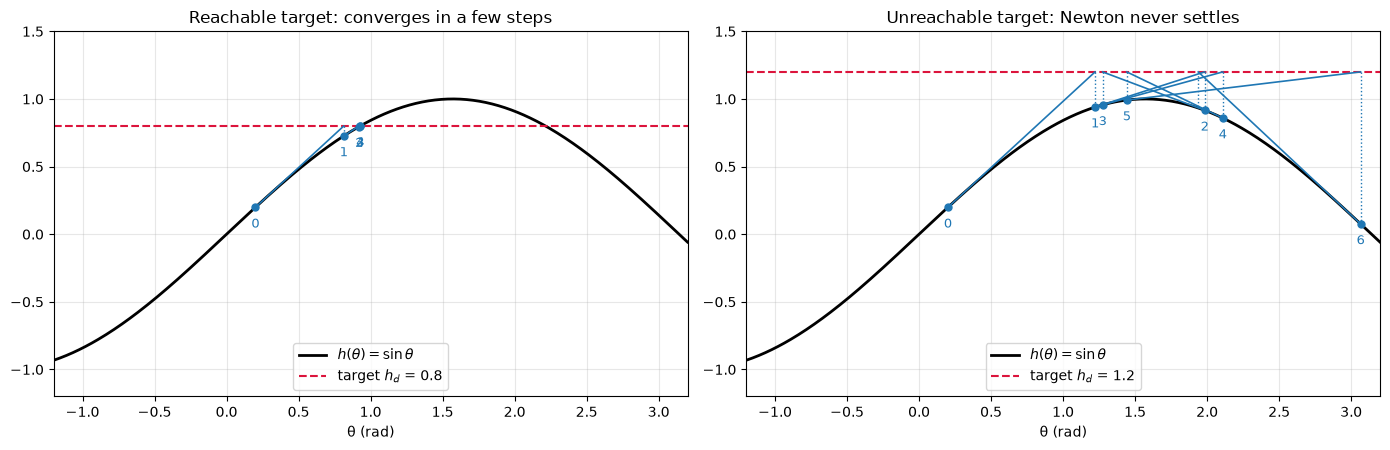

In [19]:
def newton_1d(h_d, th0, iters):
    th = [th0]
    for _ in range(iters):
        th.append(th[-1] + (h_d - np.sin(th[-1])) / np.cos(th[-1]))   # θ += J^{-1} e,  J = cos θ
    return np.array(th)


fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
grid = np.linspace(-1.2, 3.2, 400)
for ax, h_d, iters in [(axes[0], 0.8, 5), (axes[1], 1.2, 7)]:
    th = newton_1d(h_d, 0.2, iters)
    ax.plot(grid, np.sin(grid), 'k', lw=2, label=r'$h(\theta) = \sin\theta$')
    ax.axhline(h_d, color='crimson', ls='--', label=f'target $h_d$ = {h_d}')
    for k in range(iters):
        t0, t1 = th[k], th[k + 1]
        if abs(t1) > 3.2:
            ax.annotate(f'step {k + 1} jumps to θ = {t1:.1f}', xy=(t0, np.sin(t0)), xytext=(t0 - 1.3, -0.7),
                        arrowprops=dict(arrowstyle='->'), fontsize=10)
            break
        ax.plot([t0, t1], [np.sin(t0), h_d], color='tab:blue', lw=1.2)         # tangent line
        ax.plot([t1, t1], [h_d, np.sin(t1)], ':', color='tab:blue', lw=1)
        ax.plot(t0, np.sin(t0), 'o', color='tab:blue', ms=5)
        ax.text(t0, np.sin(t0) - 0.15, str(k), fontsize=9, color='tab:blue', ha='center')
    ax.set_xlim(-1.2, 3.2); ax.set_ylim(-1.2, 1.5); ax.grid(alpha=0.3); ax.set_xlabel('θ (rad)')
    ax.legend(loc='lower center')
print('h_d = 0.8 (reachable):   θ_k =', np.round(newton_1d(0.8, 0.2, 5), 6))
print('h_d = 1.2 (unreachable): θ_k =', np.round(newton_1d(1.2, 0.2, 7), 3))
axes[0].set_title('Reachable target: converges in a few steps')
axes[1].set_title('Unreachable target: Newton never settles')
plt.tight_layout(); plt.show()

### 7.5.2  Non-square Jacobians: the pseudo-inverse

When $n > m$ (a redundant robot) the equation $\mathbf{J}\Delta\boldsymbol\theta = \mathbf{e}$
has infinitely many solutions. The natural choice is the **smallest** joint step that does
the job, the minimum-norm solution

$$\Delta\boldsymbol\theta = \mathbf{J}^{+}\mathbf{e},\qquad \mathbf{J}^{+} = \mathbf{J}^\top(\mathbf{J}\mathbf{J}^\top)^{-1}.$$

When there is no exact solution ($m > n$, an unreachable target, or a singular
$\mathbf{J}$), the best we can do is the least-squares step that makes
$\|\mathbf{J}\Delta\boldsymbol\theta - \mathbf{e}\|$ as small as possible. The
**pseudo-inverse** `np.linalg.pinv(J)` (computed with the SVD) gives the right answer in
every case, and equals $\mathbf{J}^{-1}$ when $\mathbf{J}$ is square and invertible.

### 7.5.3  Jacobian transpose: gradient descent

Instead of solving equations, *minimize* the squared error
$E(\boldsymbol\theta) = \tfrac12\|\mathbf{e}(\boldsymbol\theta)\|^2$. By the chain rule its
gradient is $\nabla E = -\mathbf{J}^\top\mathbf{e}$, so a step downhill is

$$\Delta\boldsymbol\theta = \alpha\,\mathbf{J}^\top\mathbf{e}\qquad(\alpha > 0 \text{ a step size}).$$

It needs no inverse, so it is always defined, even at singularities, and it is cheap. But it
converges **slowly** (linearly), and $\alpha$ must be tuned. There is a nice physical
picture from Section 6.7: attach a spring from the gripper to the target, pulling with
force $\mathbf{F} = \mathbf{e}$. The joint torques it creates are
$\boldsymbol\tau = \mathbf{J}^\top\mathbf{F}$, and the method simply lets each joint move in
the direction of its torque.

### 7.5.4  Damped least squares (Levenberg–Marquardt)

The robust compromise looks for a step that reduces the linearized error **without being
too large**:

$$\Delta\boldsymbol\theta = \arg\min_{\Delta\boldsymbol\theta}\ \|\mathbf{J}\Delta\boldsymbol\theta - \mathbf{e}\|^2 + \lambda^2\|\Delta\boldsymbol\theta\|^2
\quad\Longrightarrow\quad
\boxed{\Delta\boldsymbol\theta = \mathbf{J}^\top\left(\mathbf{J}\mathbf{J}^\top + \lambda^2\mathbf{I}\right)^{-1}\mathbf{e}}$$

- $\lambda \to 0$: the pseudo-inverse (Newton) step, which is fast but huge near singularities.
- Large $\lambda$: $\approx \lambda^{-2}\mathbf{J}^\top\mathbf{e}$, a small, safe gradient step.
- Near a singularity, $\lambda^2\mathbf{I}$ keeps the matrix invertible and the step bounded: $\|\Delta\boldsymbol\theta\| \le \|\mathbf{e}\|/(2\lambda)$. For an unreachable target the iteration **settles near the closest reachable point** instead of oscillating, provided that bound is small (a large enough $\lambda$, or a step limit).
- Typical $\lambda$ is a few percent of the arm's size in metres. Levenberg–Marquardt variants adapt $\lambda$: increase it when a step makes the error worse, decrease it when the error drops.

| Update $\Delta\boldsymbol\theta$ | Name | Needs | Speed | Near singularity / unreachable |
|---|---|---|---|---|
| $\mathbf{J}^{-1}\mathbf{e}$ | Newton | square, invertible $\mathbf{J}$ | quadratic | fails / oscillates |
| $\mathbf{J}^{+}\mathbf{e}$ | pseudo-inverse | any $\mathbf{J}$ | quadratic | huge steps |
| $\alpha\mathbf{J}^\top\mathbf{e}$ | Jacobian transpose | step size $\alpha$ | slow | safe |
| $\mathbf{J}^\top(\mathbf{J}\mathbf{J}^\top + \lambda^2\mathbf{I})^{-1}\mathbf{e}$ | damped least squares | damping $\lambda$ | fast (slower near the solution if $\lambda$ is large) | safe, closest point |

### 7.5.5  A practical numerical IK solver

```
input: error function e(θ), task Jacobian J(θ), initial guess θ0, limits, tolerance, k_max
for k = 0, 1, ..., k_max:
    e = e(θ)
    if ||e|| < tolerance:  return θ (success)
    Δθ = Jᵀ (J Jᵀ + λ² I)⁻¹ e                      (or another rule from the table)
    if ||Δθ|| > Δ_max:  scale Δθ down to length Δ_max   (avoid wild jumps)
    θ = clamp(θ + Δθ, θ_min, θ_max)                (respect joint limits)
return θ (failure: report the remaining error)
```

Practical points:

- **Initial guess.** Use the robot's **current** joints. The solver then returns the
  solution nearest to where the robot is, which keeps the branch consistent and the motion
  smooth. To find *other* solutions, restart from random guesses.
- **Units and weights.** Position errors are in metres and angles in radians. A weight
  matrix $\mathbf{W}$ sets what matters most:
  $\Delta\boldsymbol\theta = (\mathbf{J}^\top\mathbf{W}\mathbf{J} + \lambda^2\mathbf{I})^{-1}\mathbf{J}^\top\mathbf{W}\mathbf{e}$.
- **Joint limits.** After each step, clamp the joints into their limits. A joint pinned at
  a limit wastes every step that pushes it further out, so our solver also **freezes** such a
  joint: it zeroes that column of $\mathbf{J}$ and recomputes the step, letting the other
  joints do the work. Optimization-based IK (Section 7.5.6) builds the limits into the
  problem itself.
- **Always check the result.** The solver may stop at an unreachable target's closest
  point, or at a local minimum. Check $\|\mathbf{e}\|$ before sending the joints to the robot.

**Orientation error.** For full-pose tasks we cannot subtract rotation matrices. With the
current orientation $\mathbf{R} = [\mathbf{x}\ \mathbf{y}\ \mathbf{z}]$ and the desired one
$\mathbf{R}_d = [\mathbf{x}_d\ \mathbf{y}_d\ \mathbf{z}_d]$, use

$$\mathbf{e}_o = \tfrac12\left(\mathbf{x}\times\mathbf{x}_d + \mathbf{y}\times\mathbf{y}_d + \mathbf{z}\times\mathbf{z}_d\right).$$

Each cross product turns one current axis toward its desired direction, and
$\mathbf{e}_o = \mathbf{0}$ exactly when $\mathbf{R} = \mathbf{R}_d$. For a rotation by
angle $\vartheta$ about axis $\hat{\mathbf{k}}$ (Chapter 4) taking $\mathbf{R}$ to
$\mathbf{R}_d$, $\mathbf{e}_o = \sin\vartheta\,\hat{\mathbf{k}}$, so for small errors
$\mathbf{e}_o$ is the rotation vector, in the same units as $\boldsymbol\omega$. It pairs
with the angular rows $\mathbf{J}_\omega$: the full error
$\mathbf{e} = [\mathbf{p}_d - \mathbf{p};\ \mathbf{e}_o]$ goes with the $6\times n$ Jacobian.

In [20]:
def numerical_ik(error, task_jac, q0, method='dls', lam=0.01, alpha=0.5, max_step=None,
                 lo=None, hi=None, joints=None, W=None, tol=1e-10, k_max=200):
    # error(q)     -> e = x_d - x(q)         (m,)
    # task_jac(q)  -> J for the joints moved (m x len(joints))
    # joints       : indices of the joints the solver may move (default: all)
    q = np.array(q0, float)
    idx = np.arange(q.size) if joints is None else np.asarray(joints)
    hist = {'err': [], 'q': []}

    def step(J, e):
        if method == 'newton':
            return np.linalg.solve(J, e)
        if method == 'pinv':
            return np.linalg.pinv(J) @ e
        if method == 'transpose':
            return alpha * J.T @ e
        Wm = np.eye(len(e)) if W is None else np.diag(W)                # damped least squares
        return np.linalg.solve(J.T @ Wm @ J + lam**2 * np.eye(J.shape[1]), J.T @ Wm @ e)

    for k in range(k_max + 1):
        e = error(q)
        hist['err'].append(np.linalg.norm(e)); hist['q'].append(q.copy())
        if hist['err'][-1] < tol or k == k_max:
            break
        J = task_jac(q)
        dq = step(J, e)
        if lo is not None:
            # freeze joints that sit at a limit and would be pushed further out
            blocked = ((q[idx] <= lo[idx] + 1e-9) & (dq < 0)) | ((q[idx] >= hi[idx] - 1e-9) & (dq > 0))
            if blocked.any():
                J = J.copy(); J[:, blocked] = 0.0
                dq = step(J, e); dq[blocked] = 0.0
        if max_step is not None and np.linalg.norm(dq) > max_step:
            dq *= max_step / np.linalg.norm(dq)
        q[idx] += dq
        if lo is not None:
            q = np.clip(q, lo, hi)
    hist = {key: np.array(val) for key, val in hist.items()}
    hist['converged'] = hist['err'][-1] < tol
    return q, hist


def orientation_error(R, R_d):
    return 0.5 * sum(np.cross(R[:, i], R_d[:, i]) for i in range(3))


# Check: e_o = sin(angle) * axis for a known rotation
k_hat = np.array([1.0, 2.0, 2.0]) / 3
ang = np.radians(30)
K = np.array([[0, -k_hat[2], k_hat[1]], [k_hat[2], 0, -k_hat[0]], [-k_hat[1], k_hat[0], 0]])
R_turn = np.eye(3) + np.sin(ang) * K + (1 - np.cos(ang)) * K @ K           # Rodrigues (Chapter 4)
R0 = robot_ur5e.fk(np.radians([10, -50, 80, -100, -90, 20]))[:3, :3]
print('e_o            =', np.round(orientation_error(R0, R_turn @ R0), 6))
print('sin(30°) · k̂   =', np.round(np.sin(ang) * k_hat, 6))

e_o            = [0.1667 0.3333 0.3333]
sin(30°) · k̂   = [0.1667 0.3333 0.3333]


### 7.5.6  IK as optimization, and modern solvers

Damped least squares is already the solution of a small optimization problem. Modern IK
libraries make this explicit. At every step they solve a **quadratic program (QP)** for the
joint step:

$$\min_{\Delta\boldsymbol\theta}\ \sum_i w_i\,\big\|\mathbf{J}_i\Delta\boldsymbol\theta - \alpha_i\mathbf{e}_i\big\|^2 + \lambda\|\Delta\boldsymbol\theta\|^2
\quad\text{subject to}\quad
\begin{cases}
\boldsymbol\theta_{\min} \le \boldsymbol\theta + \Delta\boldsymbol\theta \le \boldsymbol\theta_{\max} & \text{joint limits}\\
|\Delta\boldsymbol\theta| \le \dot{\boldsymbol\theta}_{\max}\,\Delta t & \text{velocity limits}\\
\text{linearized distance between bodies} \ge d_{\min} & \text{collision avoidance}
\end{cases}$$

- Each **task** $i$ is a wish with a weight $w_i$ and a gain $\alpha_i$: a gripper pose (often
  position with a high weight and orientation with a lower one), a **posture** task that
  pulls the joints toward a comfortable configuration (this resolves redundancy), the center
  of mass for a humanoid, and so on. Conflicting tasks are traded off by their weights
  instead of making the solver fail.
- **Limits** are hard inequality constraints. They are never violated, unlike clamping.
- With one task and no limits, the problem reduces to damped least squares.
- Run once per control cycle with a gain $\alpha_i < 1$, it becomes **differential IK**: the
  robot follows a moving target smoothly. This is the resolved-rate idea of Section 6.6.1,
  with constraints added.

Recent open-source tools built on these ideas:

| Library | Built on | Method | Notes |
|---|---|---|---|
| **Mink** (K. Zakka) | MuJoCo | QP differential IK: tasks + limits | Python port of Pink; frame, posture and center-of-mass tasks; joint, velocity and collision limits |
| **Pink** (S. Caron) | Pinocchio | the same QP formulation | Python |
| **placo** (Rhoban) | Pinocchio | QP-based whole-body kinematics | used by LeRobot for SO-100/SO-101 end-effector control (`RobotKinematics`) |
| **TRAC-IK** (Beeson & Ames, 2015) | KDL / ROS | pseudo-inverse Newton with random restarts and an SQP solver, run in parallel | common MoveIt plugin |
| **PyRoki** (Kim et al., 2025) | JAX | Levenberg–Marquardt nonlinear least squares | CPU/GPU, batched; also motion retargeting and trajectory optimization |
| **cuRobo** (NVIDIA, 2023) | PyTorch / CUDA | many seeds optimized in parallel on the GPU | collision-free IK and motion generation |
| **IKFast** (OpenRAVE) | — | generates analytical solvers | all solutions in microseconds |

We use Mink on the SO-ARM101 in Section 7.6.2.

> **Key Takeaways — Section 7.5**
> - Numerical IK solves $\mathbf{g}(\boldsymbol\theta) = \mathbf{Y}_d - \mathbf{f}(\boldsymbol\theta) = \mathbf{0}$ by repeated linearization with the Jacobian.
> - Newton / pseudo-inverse: fast, but fragile near singularities and for unreachable targets. Jacobian transpose: safe but slow. Damped least squares: the practical default.
> - Use the current joints as the initial guess; limit the step; respect joint limits; check the final error.
> - Orientation error: $\mathbf{e}_o = \tfrac12\sum_i \mathbf{x}_i\times\mathbf{x}_{d,i}$.
> - Modern IK is a QP: weighted tasks plus hard limits (Mink, Pink, placo); GPU and batched optimizers (PyRoki, cuRobo) find many solutions in parallel.

## 7.6  Numerical Examples

### 7.6.1  Planar 2R: comparing the update rules

The task is the tip position $(x, y)$, and the task Jacobian is the top two rows of
`jacobian(robot_2R, q)`. First a reachable target, then one beyond the reach of
$L_1 + L_2 = 1.7$.

DLS with step limit ends at θ = [26.92  1.58]°, ‖e‖ = 0.5373 m; direction to target = 26.57°


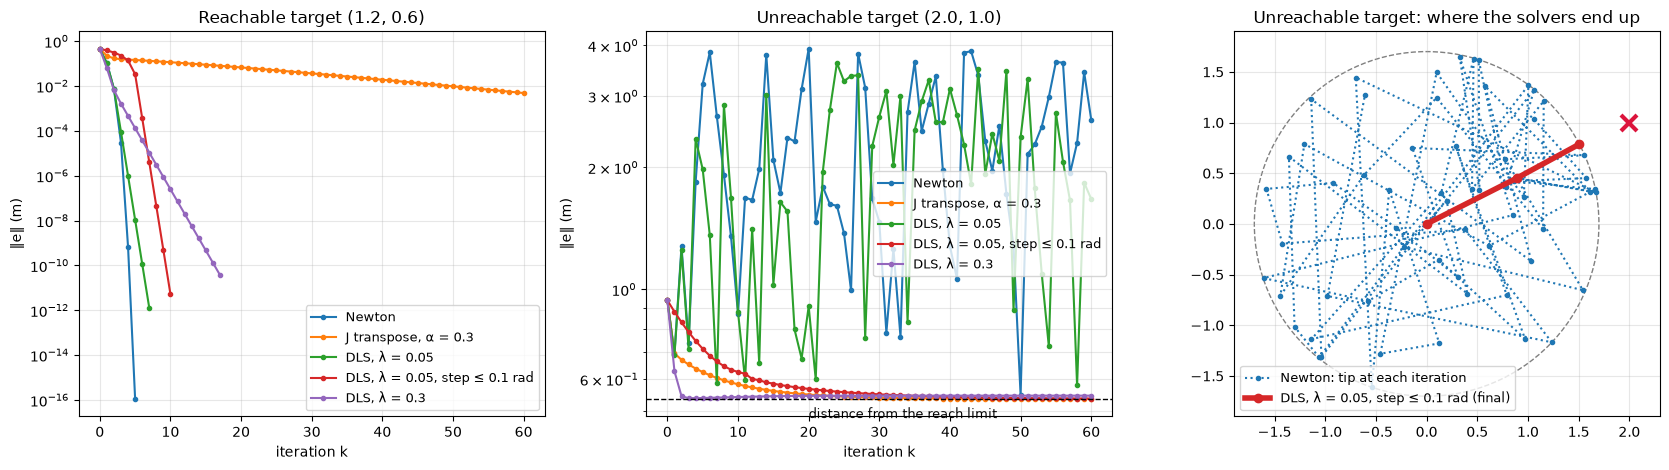

In [21]:
def make_2R_problem(x_d):
    error = lambda q: x_d - robot_2R.fk(q)[:2, 3]
    task_jac = lambda q: jacobian(robot_2R, q)[:2]
    return error, task_jac


q0 = np.radians([20, 60])
methods = [('newton', {}, 'Newton'), ('transpose', {'alpha': 0.3}, 'J transpose, α = 0.3'),
           ('dls', {'lam': 0.05}, 'DLS, λ = 0.05'),
           ('dls', {'lam': 0.05, 'max_step': 0.1}, 'DLS, λ = 0.05, step ≤ 0.1 rad'),
           ('dls', {'lam': 0.3}, 'DLS, λ = 0.3')]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, x_d, title in [(axes[0], np.array([1.2, 0.6]), 'Reachable target (1.2, 0.6)'),
                       (axes[1], np.array([2.0, 1.0]), 'Unreachable target (2.0, 1.0)')]:
    error, task_jac = make_2R_problem(x_d)
    for method, kw, label in methods:
        q, h = numerical_ik(error, task_jac, q0, method=method, k_max=60, **kw)
        ax.semilogy(h['err'], '-o', ms=3, label=label)
        if x_d[0] > 1.9:
            final = robot_2R.frames(q)
            if 'step' in label:
                pts = np.array([final[k][:2, 3] for k in ('0', '2', 'e')])
                axes[2].plot(*pts.T, '-o', lw=4, color='tab:red', label='DLS, λ = 0.05, step ≤ 0.1 rad (final)')
                print(f'DLS with step limit ends at θ = {np.round(np.degrees(wrap(q)), 2)}°, ‖e‖ = {h["err"][-1]:.4f} m; '
                      f'direction to target = {np.degrees(np.arctan2(1, 2)):.2f}°')
            if method == 'newton':
                tips = np.array([robot_2R.fk(qk)[:2, 3] for qk in h['q']])
                axes[2].plot(*tips.T, '.:', color='tab:blue', label='Newton: tip at each iteration')
    ax.set_xlabel('iteration k'); ax.set_ylabel('‖e‖ (m)'); ax.grid(alpha=0.3, which='both')
    ax.set_title(title); ax.legend(fontsize=9)
axes[1].axhline(np.linalg.norm([2.0, 1.0]) - 1.7, color='k', ls='--', lw=1)
axes[1].text(20, (np.linalg.norm([2.0, 1.0]) - 1.7) * 0.955, 'distance from the reach limit', fontsize=9, va='top')
ax = axes[2]
ax.add_patch(plt.Circle((0, 0), 1.7, fill=False, ls='--', color='0.5'))
ax.plot(2.0, 1.0, 'x', color='crimson', ms=12, mew=3)
ax.set_aspect('equal'); ax.set_xlim(-1.9, 2.3); ax.set_ylim(-1.9, 1.9); ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc='lower left'); ax.set_title('Unreachable target: where the solvers end up')
plt.tight_layout(); plt.show()

For the reachable target, Newton and lightly damped DLS converge in a handful of
iterations, with the error dropping faster and faster (quadratic convergence). Heavier
damping and the Jacobian transpose are slower.

For the unreachable target, Newton wanders around, because every step aims at a point it
can never reach. Lightly damped DLS **also** wanders: with a leftover error of 0.5 m its
step can be as large as $\|\mathbf{e}\|/(2\lambda) = 5$ rad. Limiting the step (or using a
larger $\lambda$) fixes this: DLS stretches the arm toward the target and **settles next to
the closest reachable point**, with an error equal to the distance from the reach limit.
That is the behavior a controller wants. The last centimetre is slow for $\lambda = 0.3$ and
for the transpose method, because near the stretched (singular) arm the error hardly changes
with $\theta_2$.

**Which solution do we get?** Run DLS from a grid of initial guesses and color each
starting point by the branch it converges to:

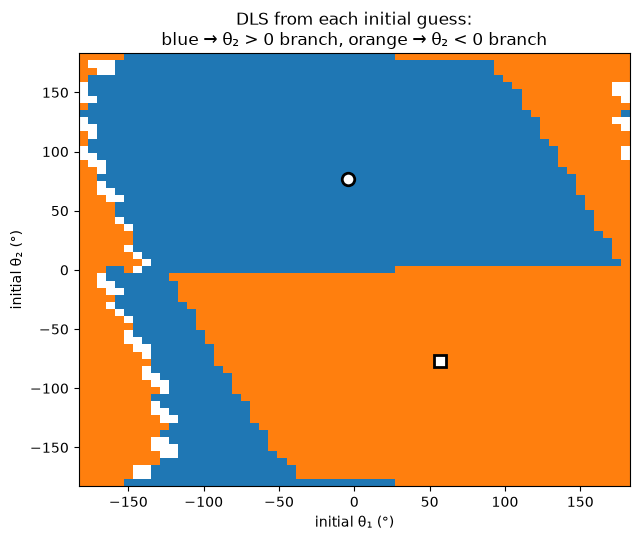

Converged from 98% of the initial guesses (white: not converged in 60 iterations)


In [22]:
error, task_jac = make_2R_problem(np.array([1.2, 0.6]))
grid = np.radians(np.linspace(-180, 180, 61))
branch = np.zeros((grid.size, grid.size))
for i, t2 in enumerate(grid):
    for j, t1 in enumerate(grid):
        q, h = numerical_ik(error, task_jac, [t1, t2], lam=0.05, max_step=0.5, k_max=60)
        branch[i, j] = np.sign(wrap(q[1])) if h['converged'] else 0

fig, ax = plt.subplots(figsize=(6.5, 5.5))
cmap = plt.matplotlib.colors.ListedColormap(['tab:orange', 'white', 'tab:blue'])
ax.pcolormesh(np.degrees(grid), np.degrees(grid), branch, cmap=cmap, vmin=-1.5, vmax=1.5, shading='nearest')
for q, mark in zip(ik_2R_all(1.2, 0.6), ('o', 's')):
    ax.plot(*np.degrees(q), mark, color='k', ms=9, mfc='white', mew=2)
ax.set_xlabel('initial θ₁ (°)'); ax.set_ylabel('initial θ₂ (°)')
ax.set_title('DLS from each initial guess:\nblue → θ₂ > 0 branch, orange → θ₂ < 0 branch')
plt.tight_layout(); plt.show()
print(f'Converged from {np.mean(branch != 0) * 100:.0f}% of the initial guesses '
      f'(white: not converged in 60 iterations)')

Mostly, the solver lands on the branch whose $\theta_2$ has the same sign as the initial
guess, but the boundary between the basins is not a straight line. This is why we start
from the robot's **current** configuration: the answer is then the one "next to" the robot.

### 7.6.2  SO-ARM101: position + pitch, numerically

The task is $\mathbf{x}(\boldsymbol\theta) = (x, y, z, \varphi)$ with the roll $\theta_5$
held at its chosen value, so we solve for $\theta_1,\dots,\theta_4$ with a $4\times4$ task
Jacobian:

- rows 1 to 3: the linear part $\mathbf{J}_v$ of the Chapter 6 Jacobian, columns 1 to 4;
- row 4: the pitch is a **linear** function of the joints, $\varphi = -(\theta_2+\theta_3+\theta_4)$
  (Section 7.4.2), so its row is simply $[0,\ -1,\ -1,\ -1]$.

In [23]:
def so101_task(q):
    return np.r_[so101.fk(q)[:3, 3], -(q[1] + q[2] + q[3])]


def so101_task_jac(q):
    J = jacobian(so101, q)                                  # 6 x 5, Chapter 6
    return np.vstack([J[:3, :4], [0, -1, -1, -1]])          # position rows + pitch row, joints 1-4


def so101_ik_numerical(p_d, phi_d, q0, **kw):
    x_d = np.r_[p_d, phi_d]
    kw = {'lam': 0.01, 'max_step': 0.5, 'lo': so101.lo, 'hi': so101.hi, **kw}
    return numerical_ik(lambda q: x_d - so101_task(q), so101_task_jac, q0, joints=[0, 1, 2, 3], **kw)


p_d, phi_d = np.array([0.25, 0.05, 0.02]), np.radians(-90)
q_num, h = so101_ik_numerical(p_d, phi_d, q0=np.zeros(5))
q_ana = so101_ik_exact(p_d, phi_d)
print(f'Converged in {len(h["err"]) - 1} iterations, final error {h["err"][-1]:.1e}')
print('numerical  θ =', np.round(np.degrees(q_num), 4), '°')
print('analytical θ =', np.round(np.degrees(q_ana), 4), '°')
print('error history:', np.array2string(h['err'], formatter={'float_kind': lambda v: f'{v:.1e}'}))

Converged in 10 iterations, final error 8.8e-12
numerical  θ = [-13.3242  19.461   -2.5863  73.1253   0.    ] °
analytical θ = [-13.3242  19.461   -2.5863  73.1253   0.    ] °
error history: [1.6e+00 1.2e+00 7.9e-01 2.3e-01 7.9e-03 4.4e-04 1.3e-05 3.8e-07 1.1e-08
 3.1e-10 8.8e-12]


Starting from home, DLS converges to the analytical (elbow-up) solution in a few
iterations. Now a **pick-and-place** sequence: each waypoint is solved starting from the
previous solution, just as a controller would. The block is a 1-inch cube on the table, so
we grasp at $z = 0.015$ m, top-down, and approach from 6 cm above.

waypoint     iters        θ1      θ2      θ3      θ4  (°)   |θ_num - θ_analytical|
above pick      11    -28.90   11.60  -14.91   93.31         1.0e-08°
pick             7    -28.90   15.27    5.77   68.95         5.4e-09°
lift             7    -28.90   11.60  -14.91   93.31         8.0e-08°
above place      9     31.82    2.21   -2.64   90.43         4.9e-08°
place            7     31.82    7.25   16.93   65.82         1.6e-09°
retreat          7     31.82    2.21   -2.64   90.43         1.1e-08°


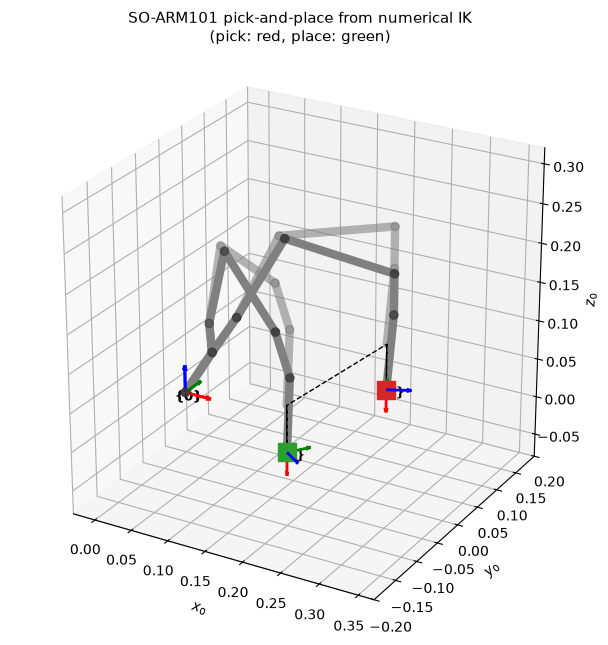

In [24]:
pick, place, lift = np.array([0.22, 0.10, 0.015]), np.array([0.20, -0.10, 0.015]), np.array([0, 0, 0.06])
waypoints = [('above pick', pick + lift), ('pick', pick), ('lift', pick + lift),
             ('above place', place + lift), ('place', place), ('retreat', place + lift)]

q = np.zeros(5)                       # start at home
sequence = []
print(f'{"waypoint":<12} {"iters":>5}   {"θ1":>7} {"θ2":>7} {"θ3":>7} {"θ4":>7}  (°)   |θ_num - θ_analytical|')
for name, p_d in waypoints:
    q, h = so101_ik_numerical(p_d, np.radians(-90), q0=q)       # warm start from the previous pose
    diff = np.abs(wrap(q - so101_ik_exact(p_d, np.radians(-90)))).max()
    sequence.append(q.copy())
    print(f'{name:<12} {len(h["err"]) - 1:5d}   ' + ' '.join(f'{v:7.2f}' for v in np.degrees(q[:4]))
          + f'         {np.degrees(diff):.1e}°')

fig = plt.figure(figsize=(8, 6.5))
ax = fig.add_subplot(111, projection='3d')
for k, qk in enumerate(sequence):
    plot_robot(ax, so101, qk, scale=0.03, alpha=1.0 if k in (1, 4) else 0.35)
for p, col in [(pick, 'tab:red'), (place, 'tab:green')]:
    ax.scatter(*p, s=150, marker='s', color=col)
path = np.array([so101.fk(qk)[:3, 3] for qk in sequence])
ax.plot(*path.T, 'k--', lw=1)
setup_3d(ax, title='SO-ARM101 pick-and-place from numerical IK\n(pick: red, place: green)', **view_so101)
plt.tight_layout(); plt.show()

**When the analytical answer breaks a limit.** Hovering 10 cm above the table at
$\mathbf{p}_d = (0.20, 0, 0.10)$ m, a top-down pose needs $\theta_4 \approx 99^\circ$, past
the $95^\circ$ wrist limit. The analytical formula happily returns that infeasible answer.
The numerical solver keeps $\theta_4$ at $95^\circ$ and finds the **best compromise**
between position and pitch, and the weights $\mathbf{W} = \mathrm{diag}(1, 1, 1, w_\varphi)$
decide what "best" means. A smaller pitch weight says *position matters more*: the gripper
tilts a little more and lands closer to the target. (Units: $w_\varphi$ trades metres²
against radians².)

In [25]:
p_high, phi_d = np.array([0.20, 0.0, 0.10]), np.radians(-90)
print('Analytical:')
report_so101(so101_ik_exact(p_high, phi_d), p_high)
print(f'\n{"pitch weight":>12}   {"position error":>14}   {"pitch":>8}   θ1..θ4 (°)')
for w_phi in (1.0, 0.01, 1e-4):
    q, h = so101_ik_numerical(p_high, phi_d, q0=np.zeros(5), W=[1, 1, 1, w_phi], k_max=300)
    T = so101.fk(q)
    print(f'{w_phi:12g}   {np.linalg.norm(T[:3, 3] - p_high) * 1000:11.3f} mm   {np.degrees(pitch(T)):7.2f}°   '
          + np.array2string(np.round(np.degrees(q[:4]), 2)))

Analytical:
    shoulder_pan      -0.00°
    shoulder_lift    -10.83°
    elbow_flex         1.58°
    wrist_flex        99.24°   <-- outside [-95.0, 95.0]°
    wrist_roll         0.00°
    FK: p = [ 0.2 -0.   0.1] m, pitch = -90.00°   (position error 0.0000 mm)

pitch weight   position error      pitch   θ1..θ4 (°)
           1         9.613 mm    -89.93°   [ -0.   -11.89   6.82  95.  ]
        0.01         3.610 mm    -87.30°   [ -0.   -14.84   7.14  95.  ]
      0.0001         0.057 mm    -85.74°   [ -0.   -16.68   7.42  95.  ]


**The same problem with Mink.** Mink formulates it as the QP of Section 7.5.6, directly on
the SO-ARM101 MuJoCo model. We give it two tasks and one limit:

- a `FrameTask` on the `gripperframe` site: position cost 1. The orientation cost is
  $[0, 0.1, 0.1]$ on the site's local axes: zero about $\mathbf{x}_e$ (the roll is free),
  and nonzero about the other two axes, so only the **pointing direction** of $\mathbf{x}_e$
  is constrained. The target orientation points $\mathbf{x}_e$ straight down;
- a weak `PostureTask` that keeps the joints near home (with a larger cost on the roll joint, which
  nothing else pins down);
- a `ConfigurationLimit`: the joint limits as hard constraints.

Each call of `solve_ik` returns a joint velocity; `integrate_inplace` takes the step. The
cell runs only if `mink` is installed (`pip install mink daqp`) and `MODEL_PATH` points to
the SO-ARM101 MuJoCo model (`scene.xml` in the `Simulation/SO101` folder of TheRobotStudio's
SO-ARM100 repository).

In [26]:
MODEL_PATH = Path('model/scene.xml')            # the SO-ARM101 MuJoCo model: set this to your copy
try:
    import mujoco
    import mink
    HAVE_MINK = MODEL_PATH.exists()
except ImportError:
    HAVE_MINK = False

if not HAVE_MINK:
    print('Skipped: install mink and daqp (pip install mink daqp) and set MODEL_PATH to the SO-ARM101 scene.xml.')
else:
    model = mujoco.MjModel.from_xml_path(str(MODEL_PATH))
    data = mujoco.MjData(model)

    # Our SO101 chain vs. MuJoCo's own forward kinematics
    rng, worst = np.random.default_rng(0), 0.0
    for _ in range(500):
        q = rng.uniform(so101.lo, so101.hi)
        data.qpos[:5] = q
        mujoco.mj_forward(model, data)
        T = so101.fk(q)
        worst = max(worst, np.abs(T[:3, 3] - data.site('gripperframe').xpos).max(),
                    np.abs(T[:3, :3] - data.site('gripperframe').xmat.reshape(3, 3)).max())
    print(f'SO101 chain vs. MuJoCo gripperframe, 500 random poses: max difference {worst:.1e}\n')

    R_down = np.array([[0, 0, 1], [0, 1, 0], [-1, 0, 0]])       # x_e pointing along -z0

    def mink_ik(p_d, iters=300, dt=0.02):
        configuration = mink.Configuration(model)               # starts at home
        grip = mink.FrameTask('gripperframe', 'site', position_cost=1.0, orientation_cost=[0.0, 0.1, 0.1])
        grip.set_target(mink.SE3.from_rotation_and_translation(mink.SO3.from_matrix(R_down), p_d))
        posture = mink.PostureTask(model, cost=[1e-3, 1e-3, 1e-3, 1e-3, 0.1, 1e-3])   # roll held more firmly
        posture.set_target_from_configuration(configuration)
        limits = [mink.ConfigurationLimit(model)]
        for _ in range(iters):
            v = mink.solve_ik(configuration, [grip, posture], dt, solver='daqp', damping=1e-3, limits=limits)
            configuration.integrate_inplace(v, dt)
        return configuration.q[:5].copy()

    for p_d in (np.array([0.25, 0.05, 0.02]), p_high):
        t0 = time.perf_counter()
        q = mink_ik(p_d)
        print(f'Mink, target {p_d} m ({(time.perf_counter() - t0) * 1000:.0f} ms for 300 QP steps):')
        report_so101(q, p_d)
        print()

Skipped: install mink and daqp (pip install mink daqp) and set MODEL_PATH to the SO-ARM101 scene.xml.


When you run the cell, Mink finds the analytical configuration for the reachable target. For
the high target it keeps the wrist at its $95^\circ$ limit, a hard constraint, and should land
close to **the compromise of our DLS with pitch weight 0.01**. That is no coincidence: a Mink cost $c$
enters the objective squared, so `orientation_cost = 0.1` is our weight
$w_\varphi = 0.01$, and both solvers minimize the same weighted error subject to the same
limit. Change the costs and the trade-off changes. That freedom is the main point of
optimization-based IK.

### 7.6.3  UR5e: full pose, and several solutions

For a 6-joint arm we can ask for the full pose. The error stacks the position error and the
orientation error of Section 7.5.5, and the task Jacobian is the full $6\times6$ Jacobian.
We take a target pose from a known configuration and run DLS from 60 random initial guesses.

60 of 60 runs converged; 8 distinct solutions (joint angles in °):
  1: [-126.8 -120.   -90.   -60.    90.    68.2]   ‖T(θ) - T_d‖ = 9e-11
  2: [-126.8 -148.7  -38.5   97.2  -90.  -111.8]   ‖T(θ) - T_d‖ = 8e-11
  3: [-126.8  174.4   38.5   57.1  -90.  -111.8]   ‖T(θ) - T_d‖ = 5e-11
  4: [-126.8  154.6   90.  -154.6   90.    68.2]   ‖T(θ) - T_d‖ = 2e-11
  5: [ 30.   25.4 -90.  -25.4 -90.   45. ]   ‖T(θ) - T_d‖ = 7e-12
  6: [  30.     5.6  -38.5  122.9   90.  -135. ]   ‖T(θ) - T_d‖ = 6e-11
  7: [  30.   -31.3   38.5   82.8   90.  -135. ]   ‖T(θ) - T_d‖ = 7e-11
  8: [  30.  -60.   90. -120.  -90.   45.]   ‖T(θ) - T_d‖ = 2e-11


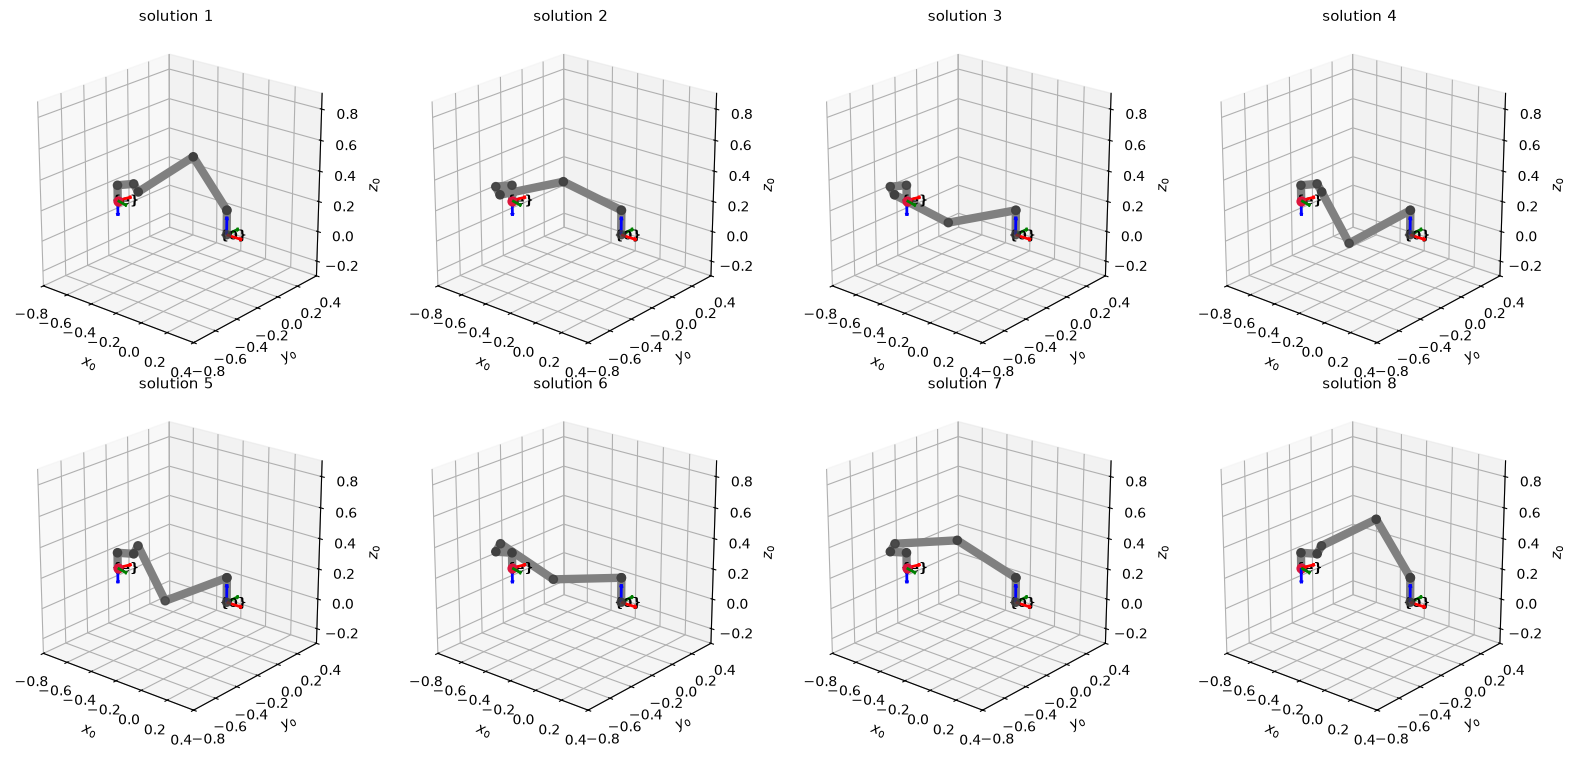

In [27]:
q_true = np.radians([30, -60, 90, -120, -90, 45])
T_d = robot_ur5e.fk(q_true)


def ur5e_error(q):
    T = robot_ur5e.fk(q)
    return np.r_[T_d[:3, 3] - T[:3, 3], orientation_error(T[:3, :3], T_d[:3, :3])]


rng = np.random.default_rng(4)
solutions, n_conv = [], 0
for _ in range(60):
    q, h = numerical_ik(ur5e_error, lambda q: jacobian(robot_ur5e, q), rng.uniform(-np.pi, np.pi, 6),
                        lam=0.05, max_step=0.5, k_max=300, tol=1e-10)
    if not h['converged']:
        continue
    n_conv += 1
    q = wrap(q)
    if not any(np.allclose(wrap(q - s), 0, atol=1e-5) for s in solutions):
        solutions.append(q)

print(f'{n_conv} of 60 runs converged; {len(solutions)} distinct solutions (joint angles in °):')
solutions.sort(key=lambda s: (np.round(s[0], 3), np.round(s[2], 3), np.round(s[4], 3)))
for k, s in enumerate(solutions):
    err = np.linalg.norm(robot_ur5e.fk(s) - T_d)
    print(f'  {k + 1}: {np.round(np.degrees(s), 1)}   ‖T(θ) - T_d‖ = {err:.0e}')

fig = plt.figure(figsize=(16, 7.5))
for k, s in enumerate(solutions[:8]):
    ax = fig.add_subplot(2, 4, k + 1, projection='3d')
    plot_robot(ax, robot_ur5e, s, scale=0.1)
    setup_3d(ax, center=(-0.2, -0.2, 0.3), half=0.6, view=(22, -50), title=f'solution {k + 1}')
    ax.scatter(*T_d[:3, 3], color='crimson', s=40)
plt.tight_layout(); plt.show()

All of these configurations put the gripper at exactly the same pose: the UR5e's eight
branches (shoulder left/right, elbow up/down, wrist flipped/not). Each run finds **one**
of them, decided by its initial guess. Random restarts are how numerical solvers such as
TRAC-IK and cuRobo find several solutions and keep the best one.

> **Key Takeaways — Section 7.6**
> - Newton and lightly damped DLS converge quadratically for reachable targets; for unreachable targets only damped methods with a bounded step settle (near the closest point).
> - The solution found depends on the initial guess, so use the robot's current joints.
> - SO-ARM101: task $(x, y, z, \varphi)$, Jacobian = $\mathbf{J}_v$ columns 1 to 4 plus the row $[0, -1, -1, -1]$. Numerical and analytical answers agree to $10^{-7}$ degrees.
> - Weights trade off conflicting goals (position vs. pitch); a QP solver such as Mink adds hard joint limits.
> - Full-pose IK with $\mathbf{e} = [\mathbf{p}_d - \mathbf{p};\ \mathbf{e}_o]$ finds the UR5e's solutions one restart at a time.

## 7.7  Analytical vs. Numerical, and Chapter Summary

| | Analytical | Numerical |
|---|---|---|
| Needs | a derivation for each robot (special structure) | forward kinematics + Jacobian only |
| Solutions | all of them, at once | one, near the initial guess |
| Time | microseconds, always the same | iterations; varies, may fail |
| Accuracy | exact | to the tolerance |
| Unreachable target | detected cleanly ($\lvert\cos\theta_2\rvert > 1$) | DLS returns the closest point: check the error |
| Singularities | formulas break: handle as special cases | damping and QP handle them gracefully |
| Joint limits, collisions, extra goals | checked afterwards | built in (QP-based IK) |
| Redundant robots | need an extra parameter | natural (pseudo-inverse, posture task) |

In practice, industrial 6-axis controllers ship analytical solvers. Research robots,
humanoids, teleoperation, and learned policies that output gripper targets (including
LeRobot on the SO-ARM101) use optimization-based differential IK. A good habit is to use
the analytical solution when you have one, to see every branch, and a numerical solver to
track targets, handle limits, and combine goals.

## Chapter 7 Summary

> - **IK** solves $\mathbf{T}_e^0(\boldsymbol\theta) = \mathbf{T}_d$, or a part of it. There may be no solution, a few (branches), or infinitely many (redundancy, singularities). Always verify with the forward kinematics.
> - **Analytical toolkit:** `atan2` of sine and cosine; the law of cosines $\cos\theta_2 = (D^2 - L_1^2 - L_2^2)/(2L_1L_2)$; $a\cos\theta + b\sin\theta = c$; decoupling through a wrist point or an arm plane.
> - **SO-ARM101 (position + pitch):** $\theta_1 = -\mathrm{atan2}(y_d, x_d - x_p)$; wrist point $W = P_d - L_3\mathbf{u}(\varphi_d + \delta)$; law of cosines for $\theta_2$, $\theta_3$ (elbow up); $\theta_4 = -\varphi_d - \theta_2 - \theta_3$; $\theta_5$ = roll. Check the limits.
> - **Numerical IK** iterates $\boldsymbol\theta \leftarrow \boldsymbol\theta + \Delta\boldsymbol\theta$ with $\Delta\boldsymbol\theta = \mathbf{J}^{-1}\mathbf{e}$ (Newton), $\mathbf{J}^+\mathbf{e}$, $\alpha\mathbf{J}^\top\mathbf{e}$, or $\mathbf{J}^\top(\mathbf{J}\mathbf{J}^\top + \lambda^2\mathbf{I})^{-1}\mathbf{e}$ (damped least squares, the practical default).
> - **Optimization-based IK** (Mink, Pink, placo, PyRoki, cuRobo): weighted tasks plus hard limits, solved as a QP or nonlinear least squares.

| Robot | Method | Key step |
|---|---|---|
| Planar 2R | analytical | law of cosines, two branches |
| Planar 3R | analytical | wrist point $\mathbf{w} = \mathbf{p}_d - L_3\mathbf{u}(\varphi_d)$ |
| SCARA | analytical | 2R + $d_3 = h - d_e - z_d$ + $\theta_4 = \theta_1+\theta_2-\varphi_d$ |
| Spherical wrist | analytical | ZYZ angles from $\mathbf{R}_d$; singular at $s_2 = 0$ |
| SO-ARM101 | analytical and numerical | arm plane + wrist point; $4\times4$ task Jacobian |
| UR5e | numerical | full-pose DLS with $\mathbf{e}_o$; random restarts find the branches |

### Practice problems

1. Planar 2R with $L_1 = 1$, $L_2 = 0.7$: find both IK solutions for the target $(0.5, 1.2)$ by hand, and check them with `robot_2R.fk`.
2. Planar 3R with $L = (1, 0.7, 0.3)$: for $(x_d, y_d, \varphi_d) = (0.8, 1.0, 90^\circ)$, compute the wrist point and both solutions.
3. Spherical wrist: find all solutions for $\mathbf{R}_d = \mathbf{R}_z(30^\circ)\mathbf{R}_y(-45^\circ)\mathbf{R}_z(60^\circ)$. What happens for $\mathbf{R}_d = \mathbf{R}_z(90^\circ)$?
4. SO-ARM101: using the constants printed in Section 7.4.2, compute by hand the top-down ($\varphi_d = -90^\circ$) solution for $\mathbf{p}_d = (0.22, 0.05, 0.02)$ m, and check it with `so101_ik`. Which joint limit stops a top-down grasp as the target moves farther out?
5. Run DLS on the 2R arm for the unreachable target $(2.0, 1.0)$ with $\lambda = 0.001$, $0.05$ and $0.5$. Explain the differences using the table in Section 7.5.4.